In [1]:
import sys, yaml
sys.path.append("..")

import numpy as np

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from models import TemporalSatCLIPEncoder

temporal_satclip_config = "../../conf/model/t_satclip/t_satclip_doy_1M.yaml"

In [4]:
with open(temporal_satclip_config) as f:
    cfg = yaml.safe_load(f)

kwargs = cfg["kwargs"]

In [5]:
encoder = TemporalSatCLIPEncoder(
    ckpt_path=kwargs["ckpt_path"],
    repo_path=kwargs["repo_path"],
    model_name=kwargs["model_name"],
    device="cpu",
)

/u/lbetti/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/u/lbetti/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


using pretrained moco vit16
using loss function: satclip_loss
using temporal model: True


## Try on one location

In [6]:
lat, lon = 40.0150, -105.2705  # Boulder, Colorado

In [7]:
# Daily timestamps for 2017
dates = pd.date_range("2017-01-01", "2017-12-31", freq="D")
timestamps = dates.astype("datetime64[s]").astype(np.int64)


In [8]:
timestamps

Index([1483228800, 1483315200, 1483401600, 1483488000, 1483574400, 1483660800,
       1483747200, 1483833600, 1483920000, 1484006400,
       ...
       1513900800, 1513987200, 1514073600, 1514160000, 1514246400, 1514332800,
       1514419200, 1514505600, 1514592000, 1514678400],
      dtype='int64', length=365)

In [9]:
lons = np.full(len(timestamps), lon)
lats = np.full(len(timestamps), lat)

embeddings = encoder.encode(lons, lats, posix_timestamp=timestamps)

In [10]:
embeddings

array([[ 0.5250335 ,  1.5280606 , -1.7651113 , ..., -1.0361959 ,
        -1.7338755 ,  0.15708134],
       [ 0.5001639 ,  1.5194061 , -1.7682858 , ..., -1.0507965 ,
        -1.735602  ,  0.14972976],
       [ 0.47559276,  1.5107914 , -1.7712411 , ..., -1.0652767 ,
        -1.7378352 ,  0.14311431],
       ...,
       [ 0.48536548,  1.500127  , -1.7476029 , ..., -0.9269021 ,
        -1.7312846 ,  0.13832365],
       [ 0.46628278,  1.4827329 , -1.759269  , ..., -0.9427391 ,
        -1.7268336 ,  0.13662122],
       [ 0.44725823,  1.4655837 , -1.7707824 , ..., -0.9580995 ,
        -1.7229886 ,  0.13519585]], shape=(365, 256), dtype=float32)

### Visualize per channel

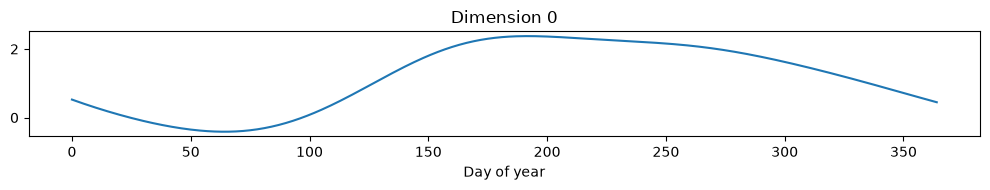

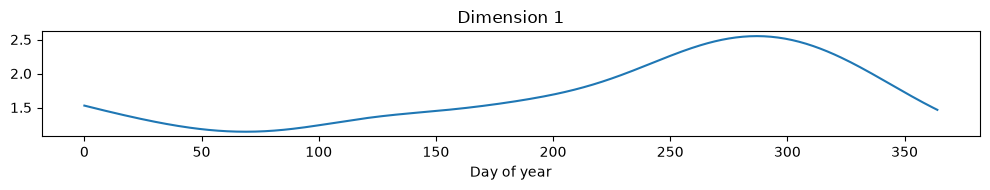

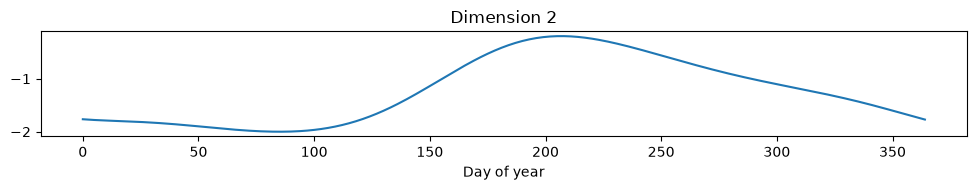

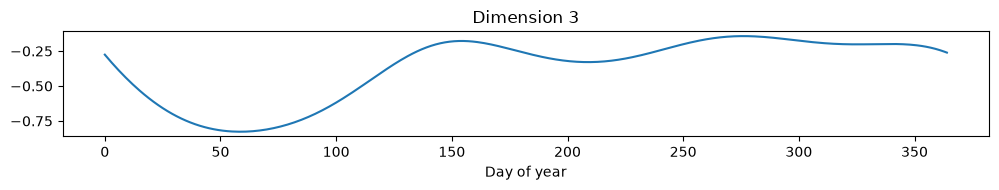

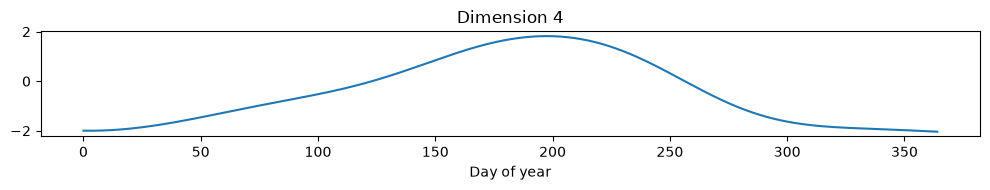

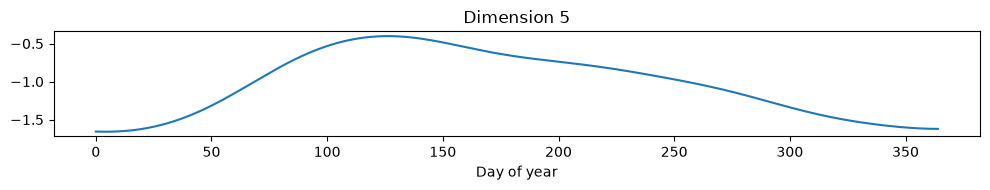

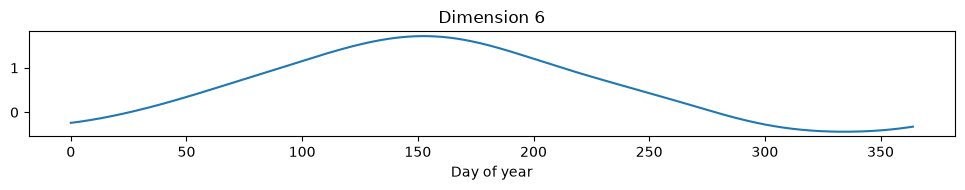

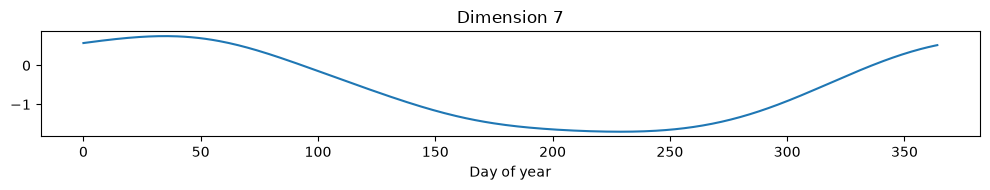

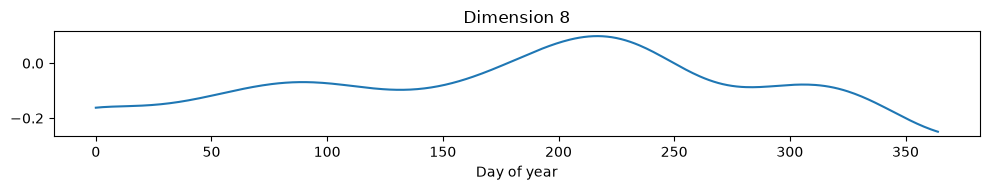

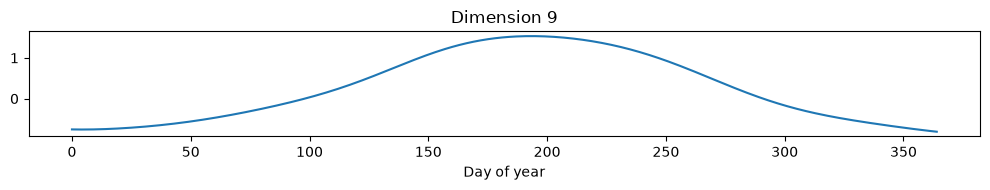

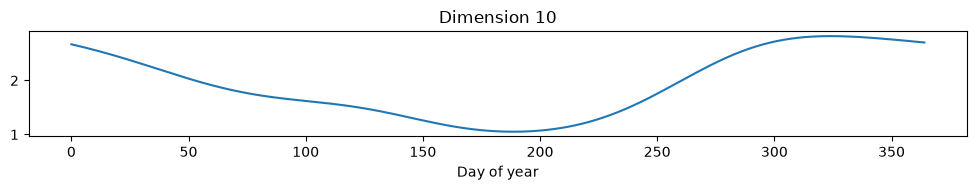

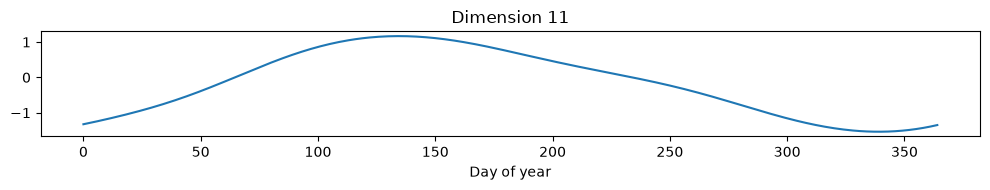

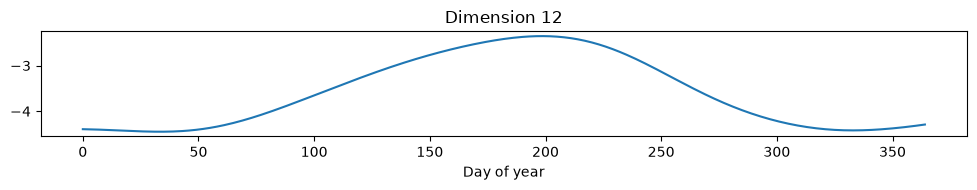

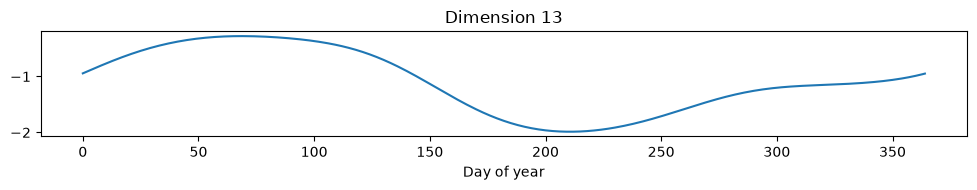

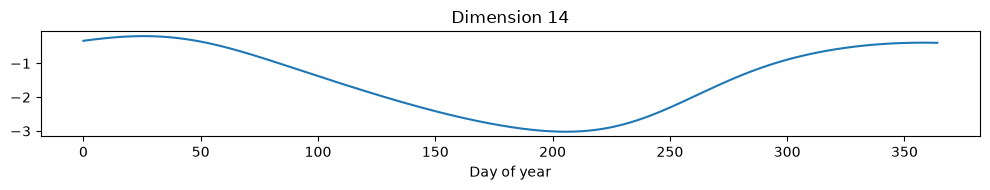

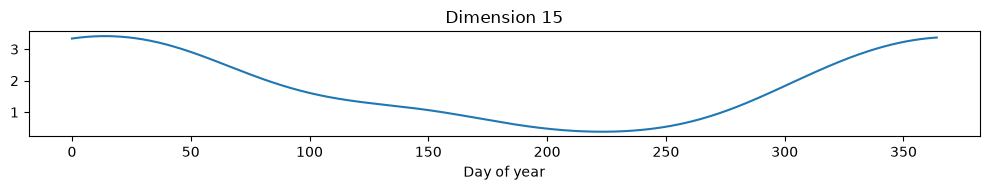

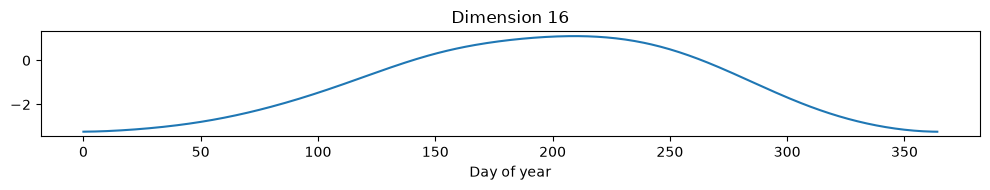

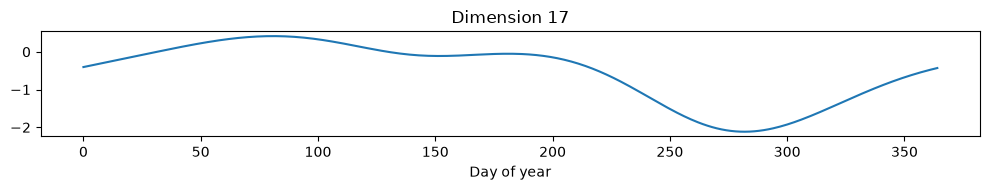

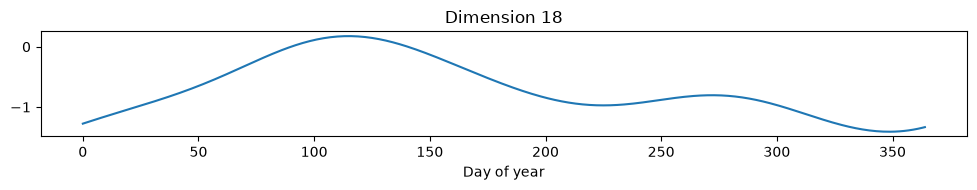

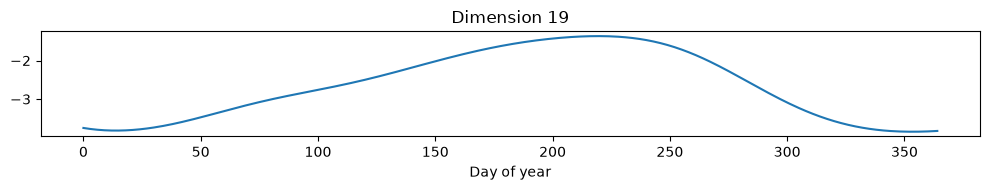

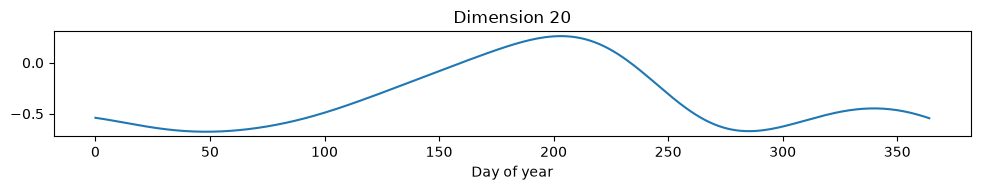

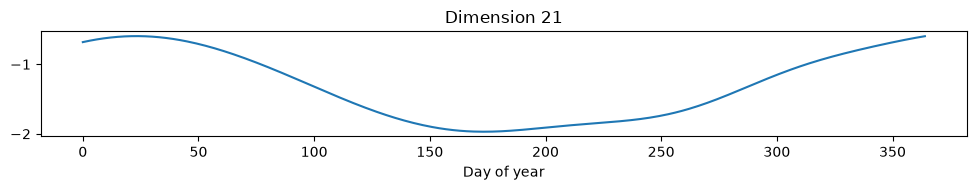

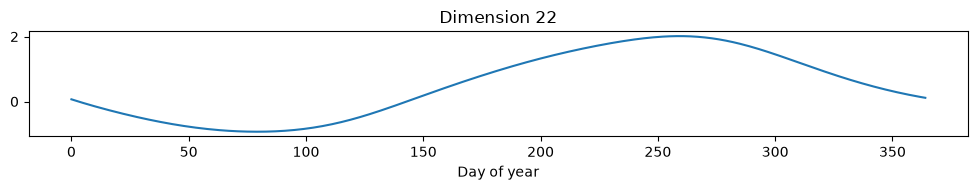

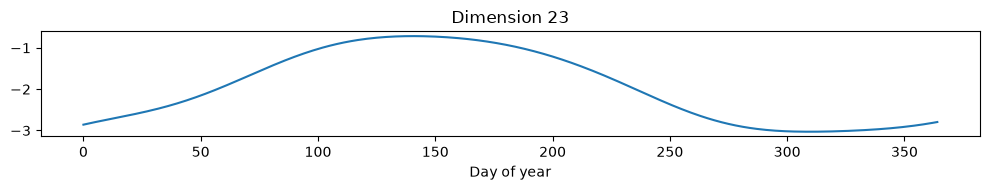

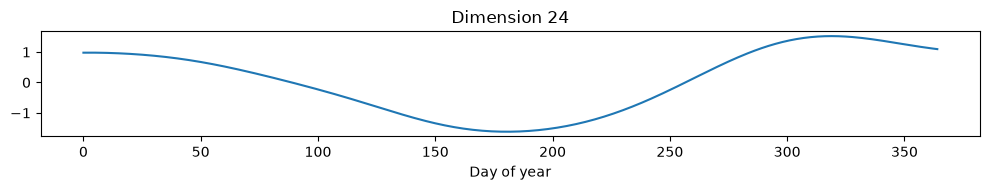

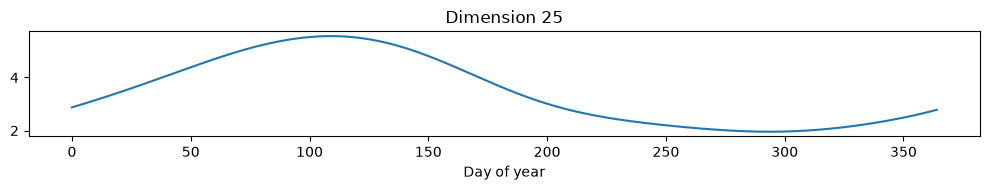

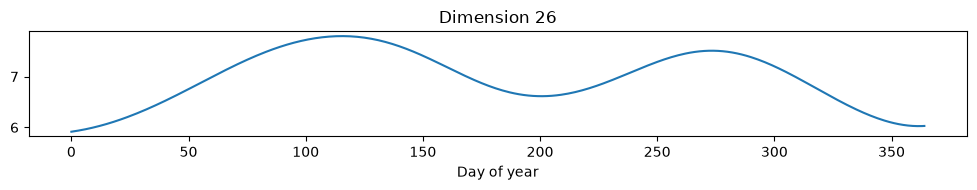

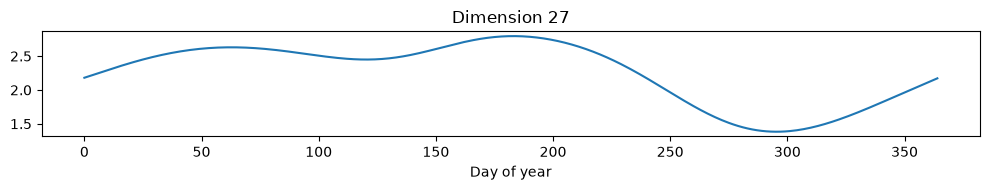

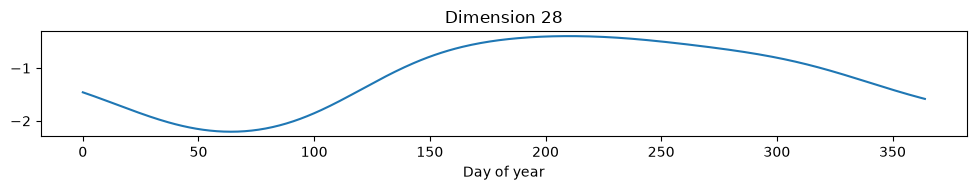

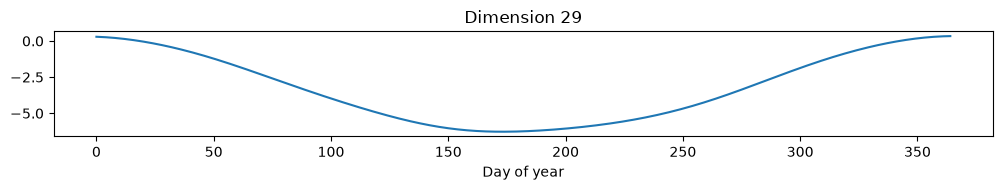

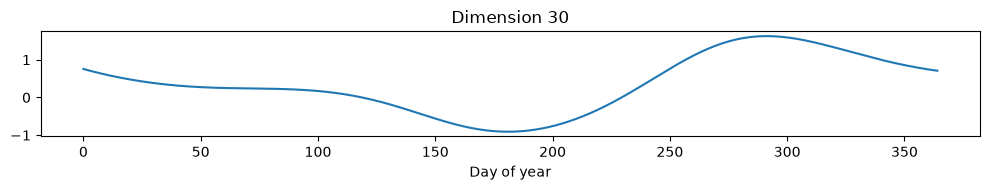

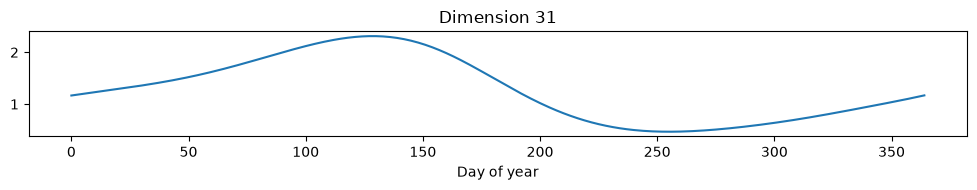

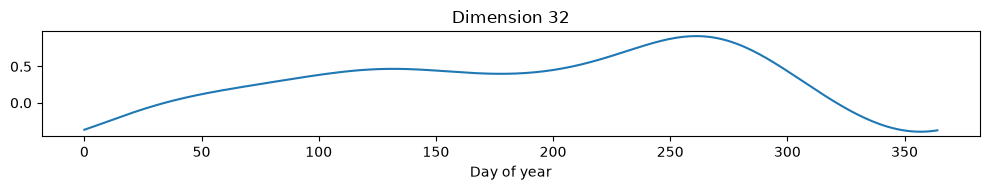

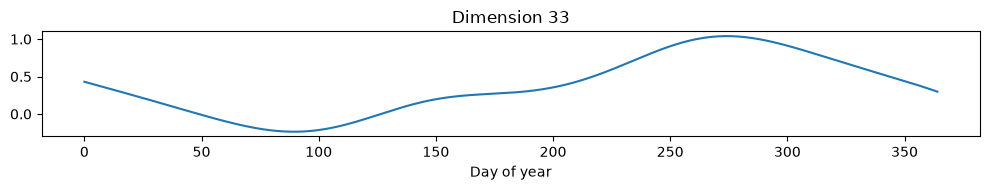

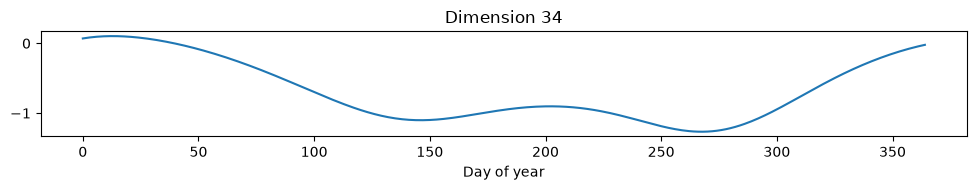

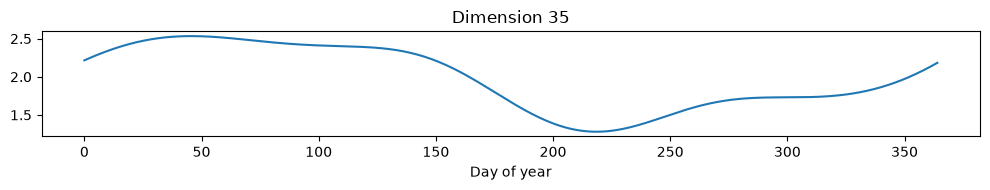

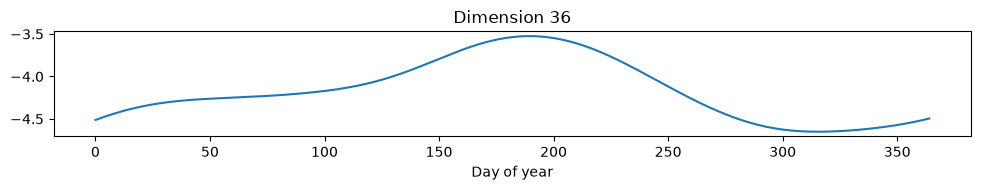

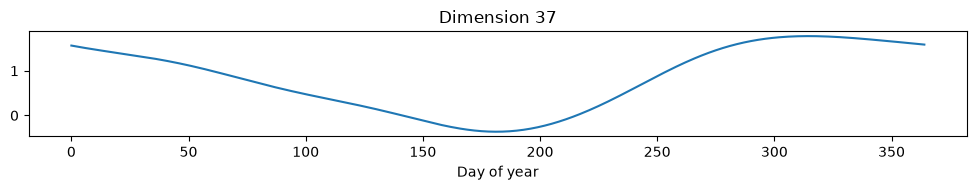

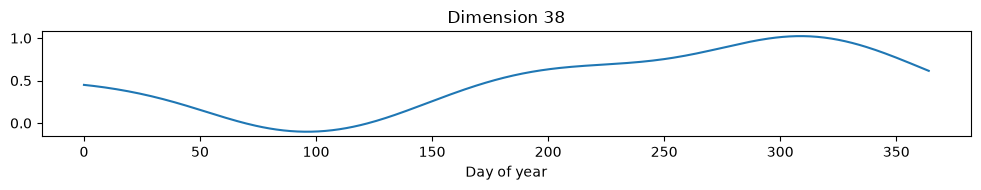

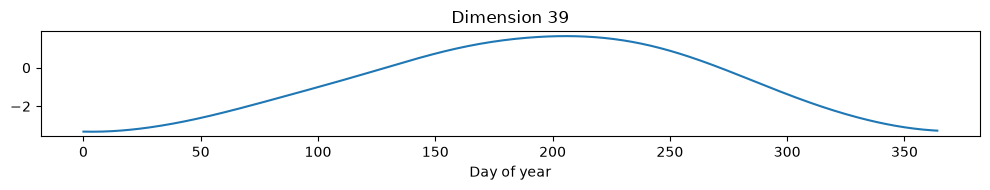

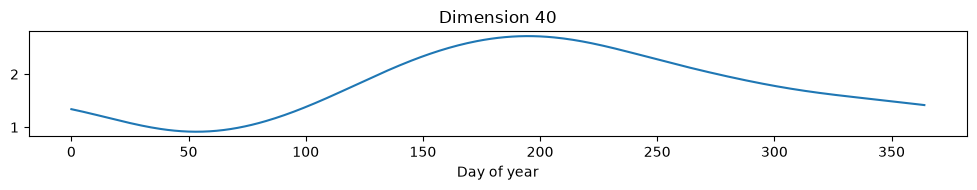

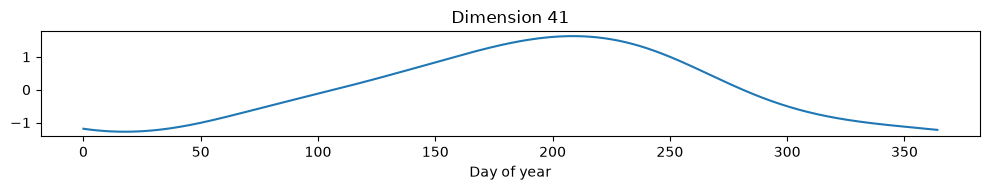

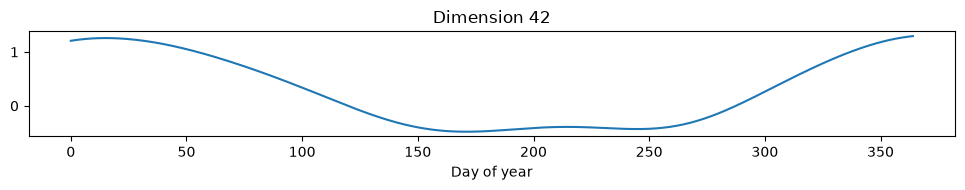

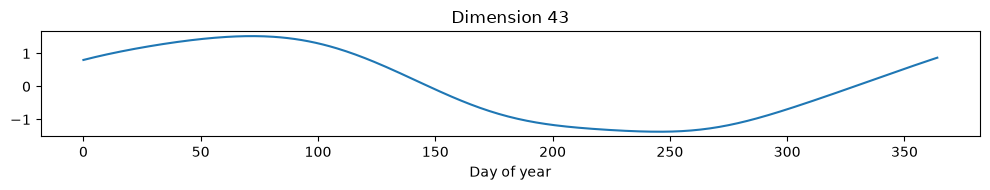

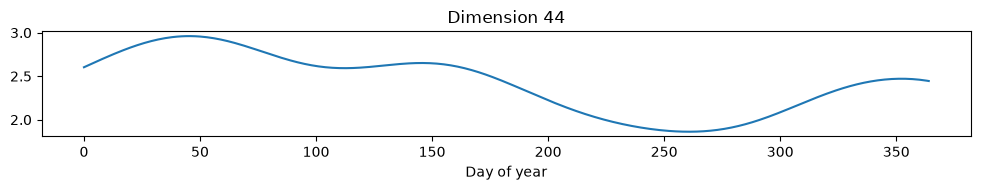

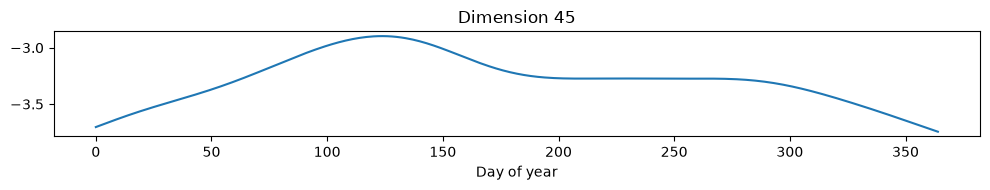

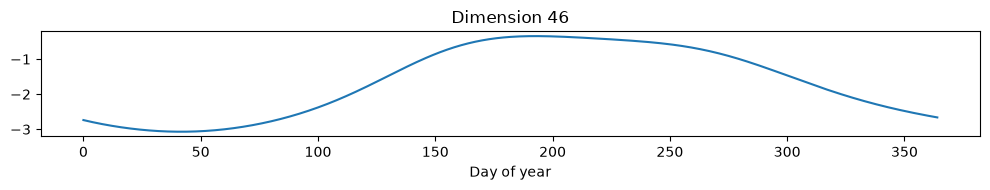

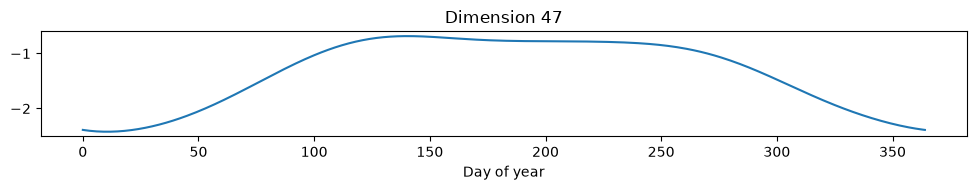

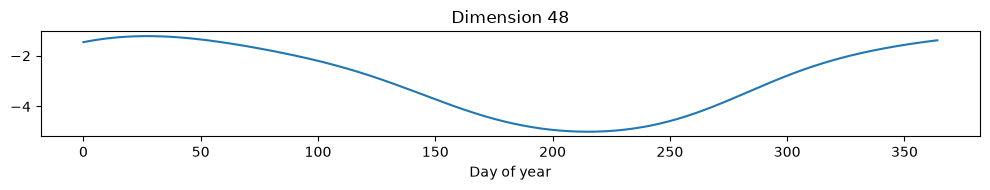

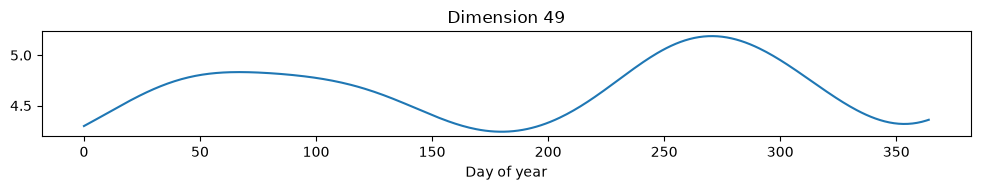

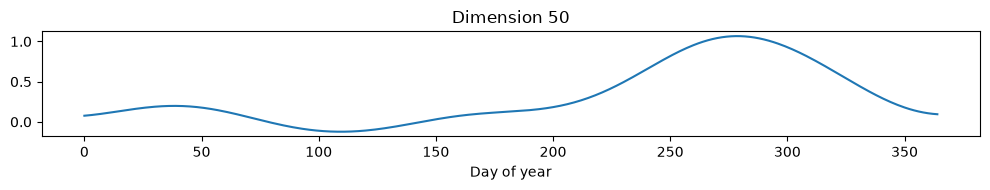

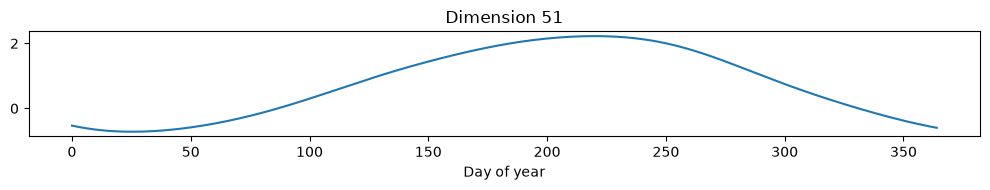

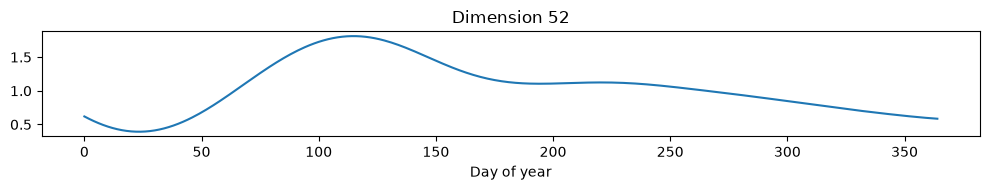

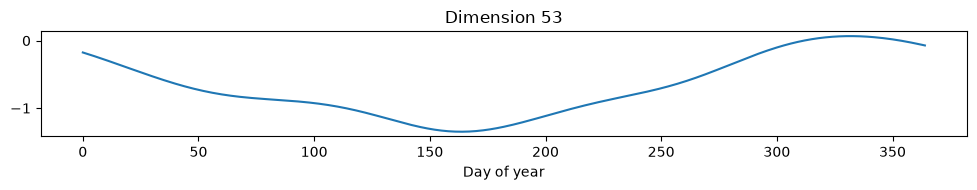

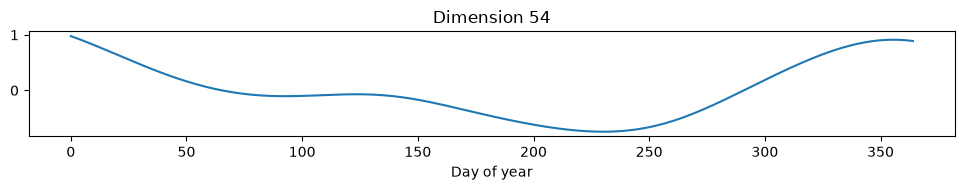

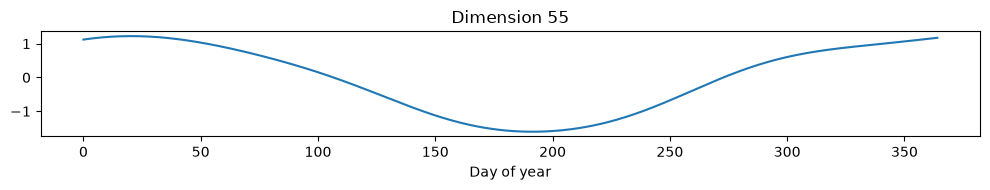

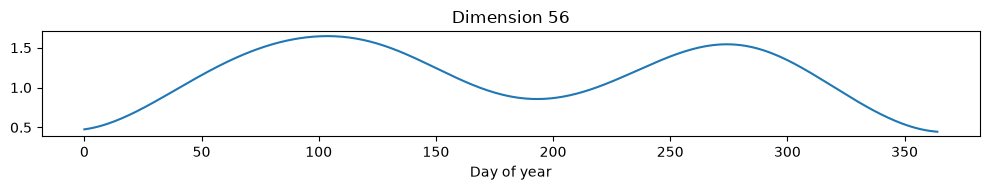

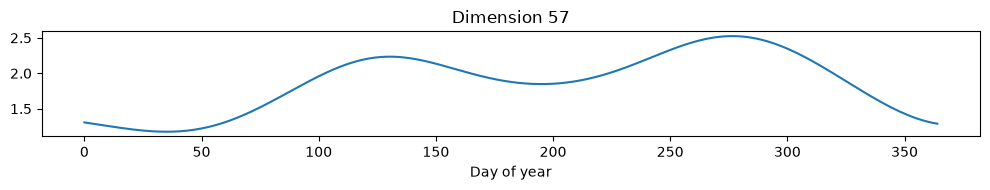

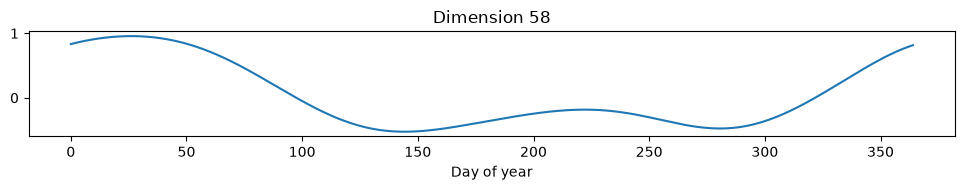

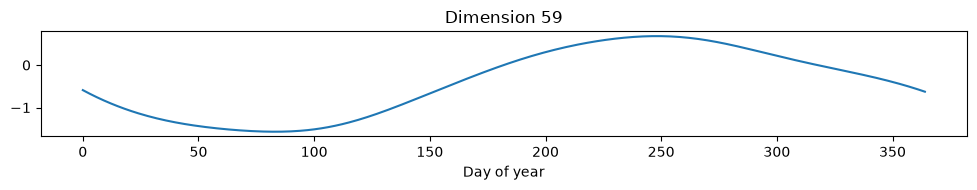

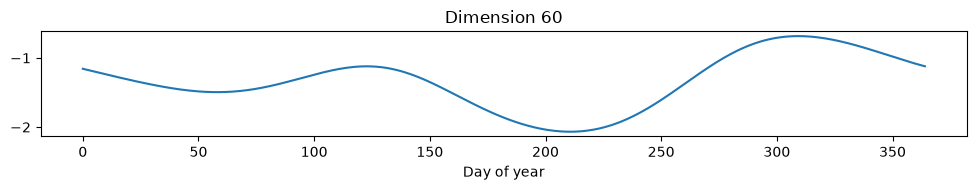

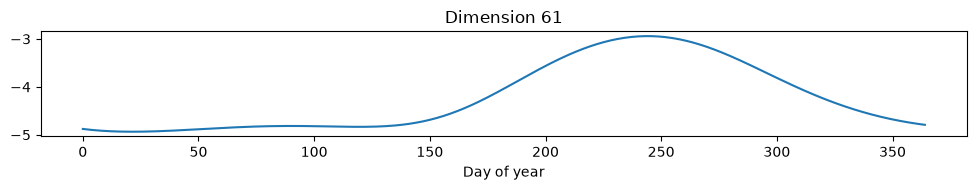

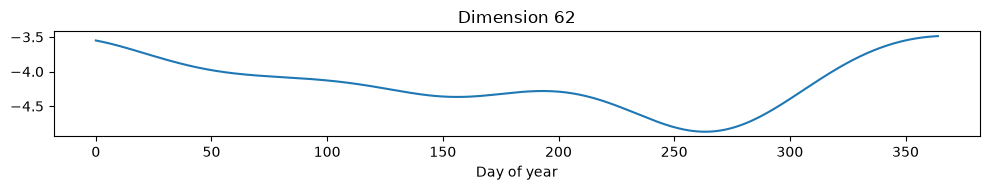

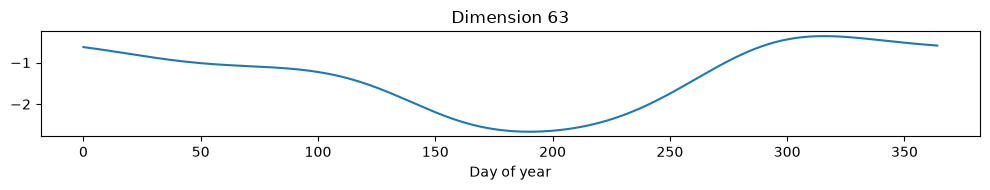

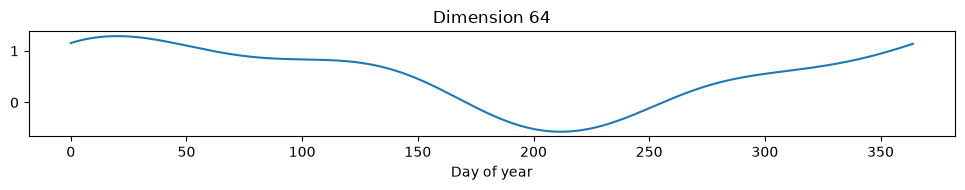

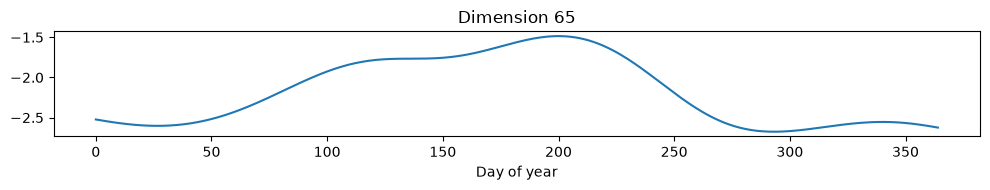

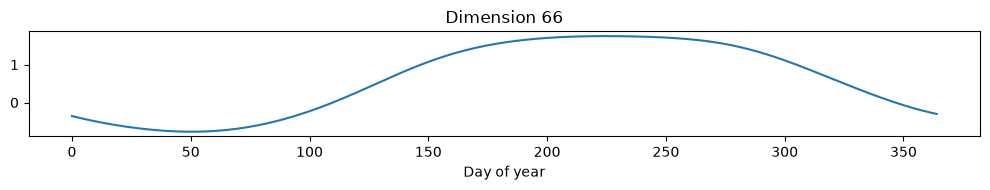

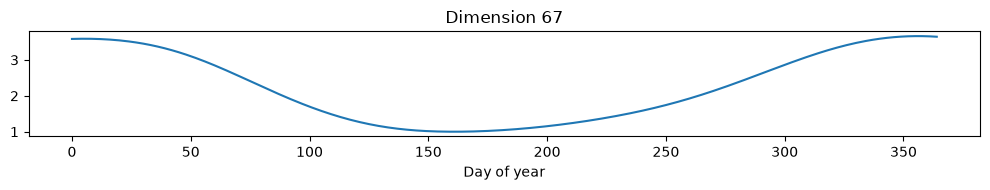

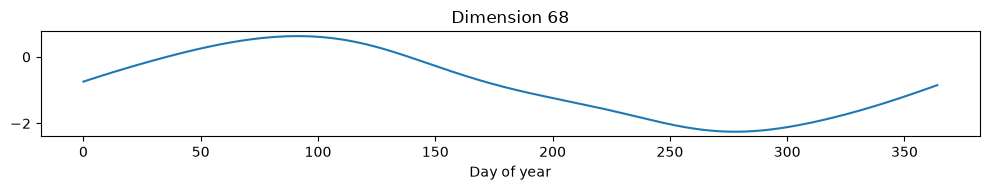

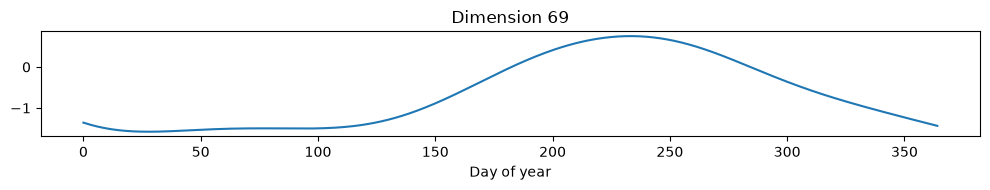

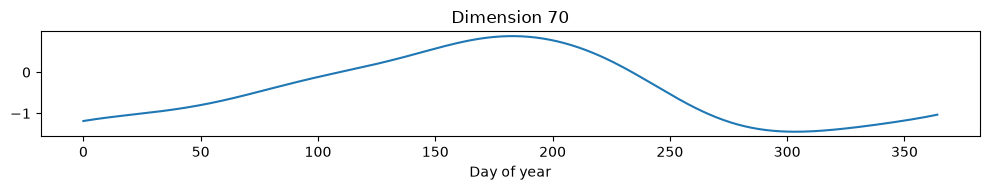

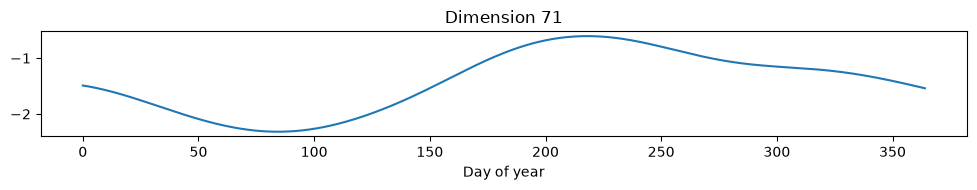

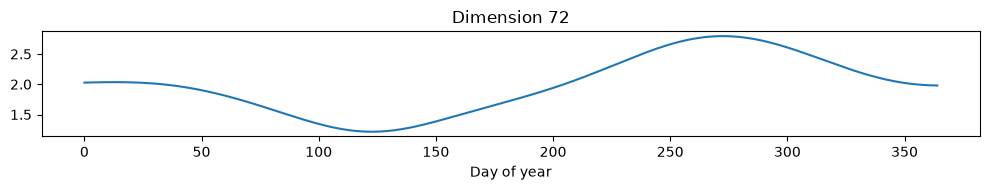

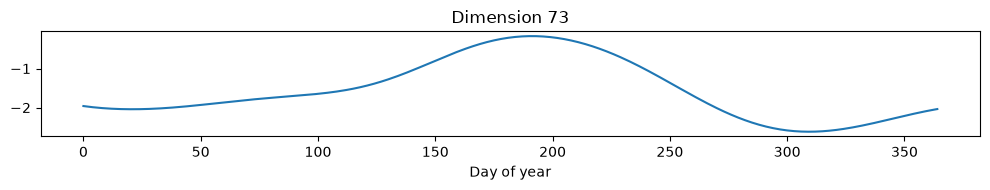

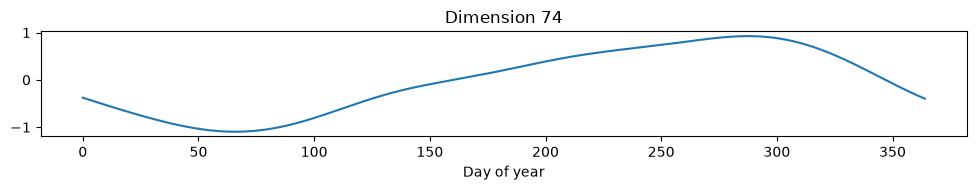

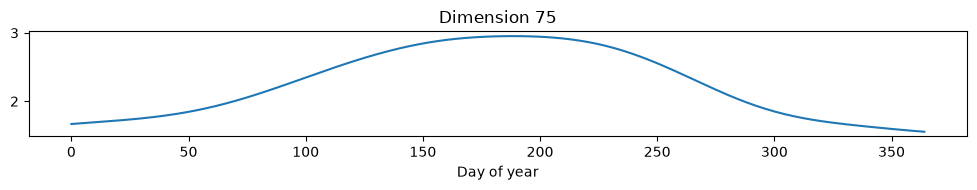

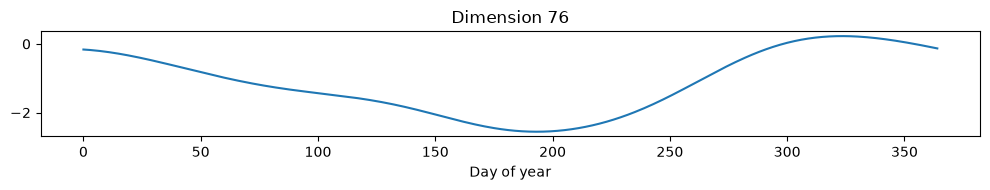

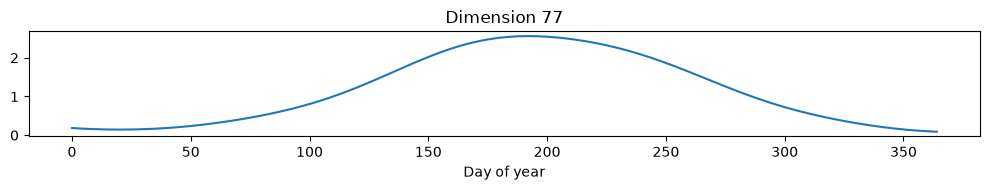

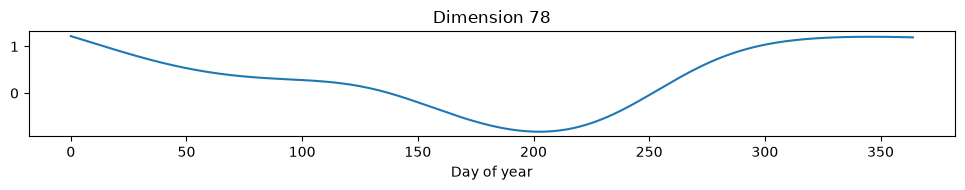

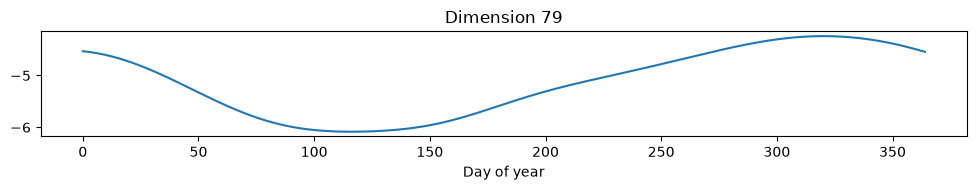

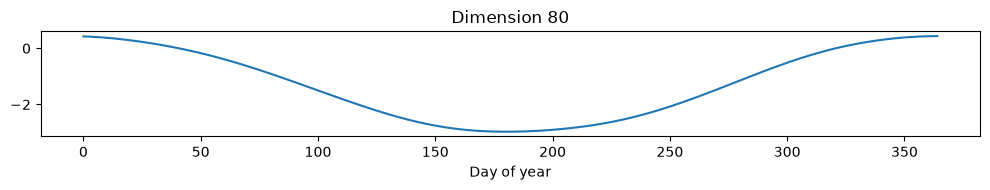

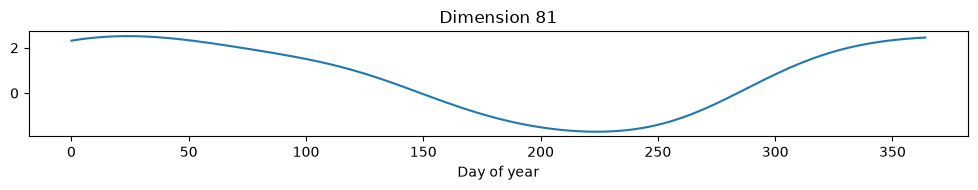

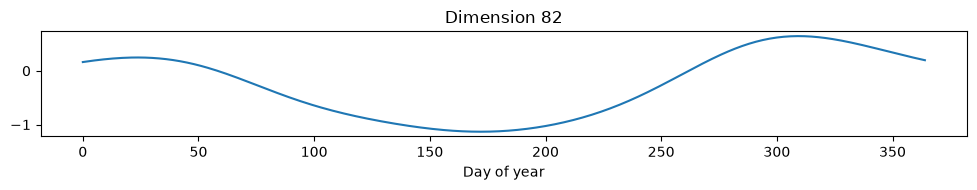

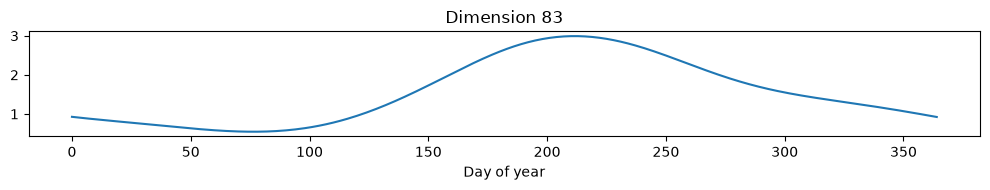

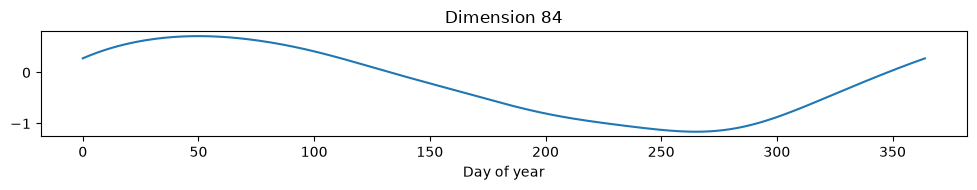

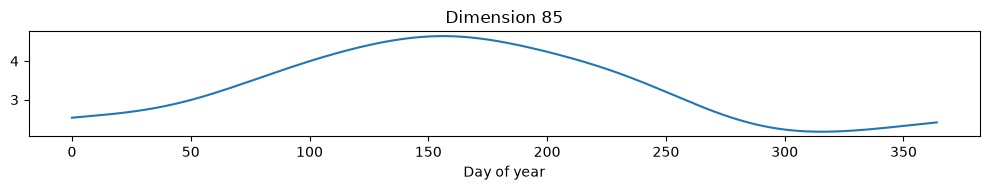

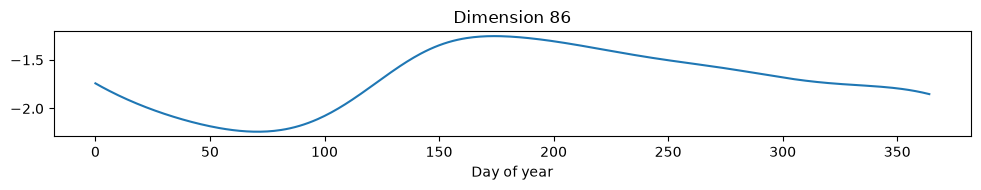

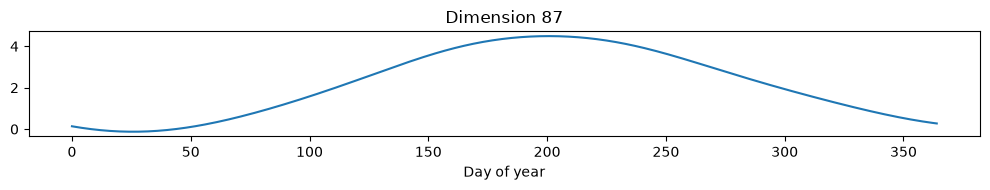

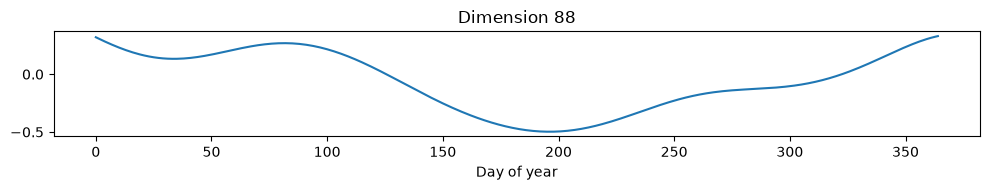

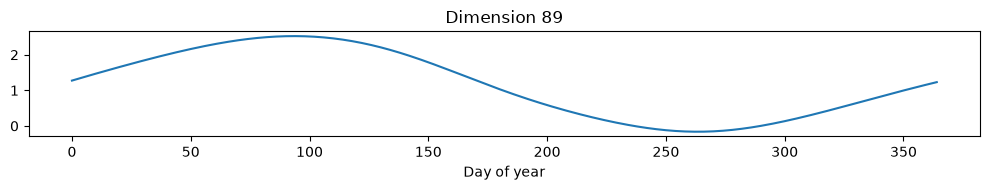

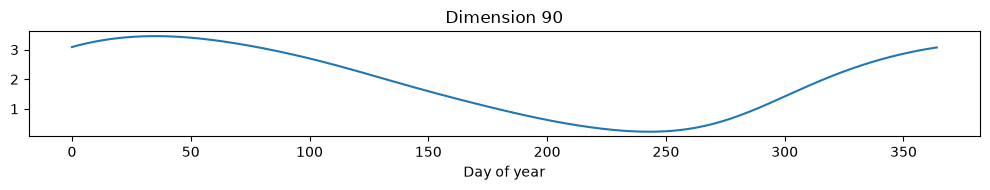

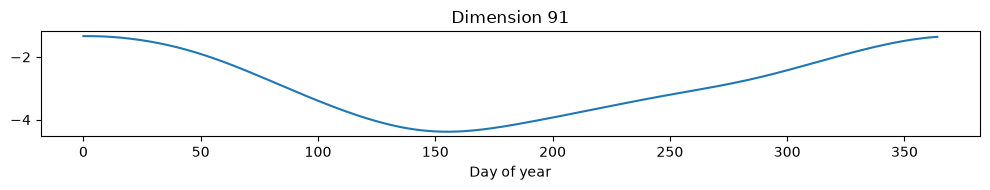

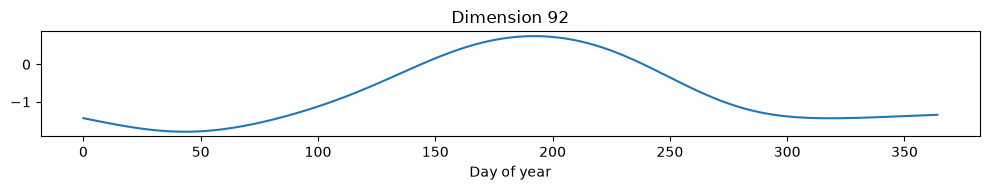

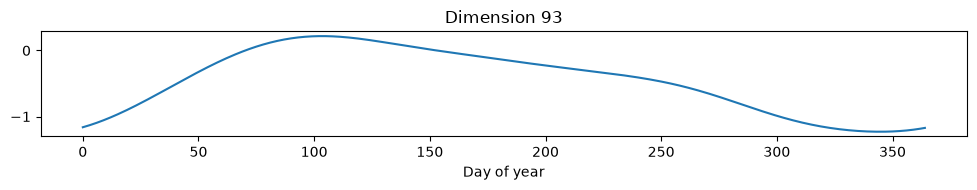

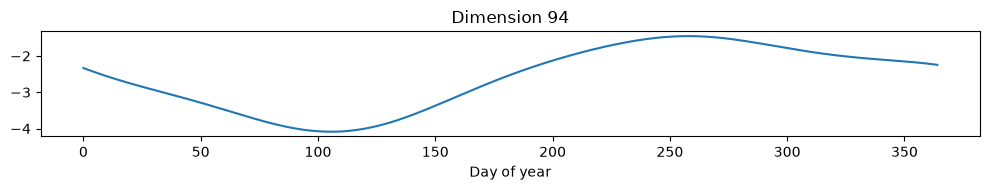

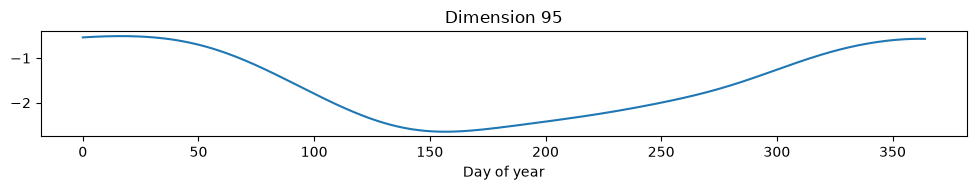

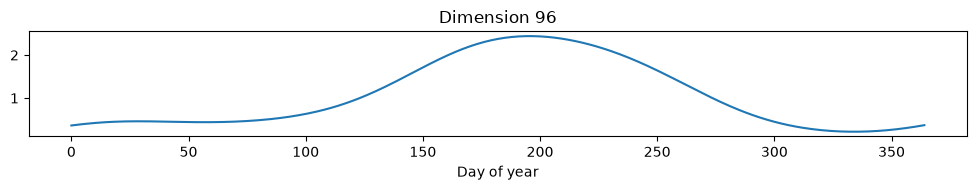

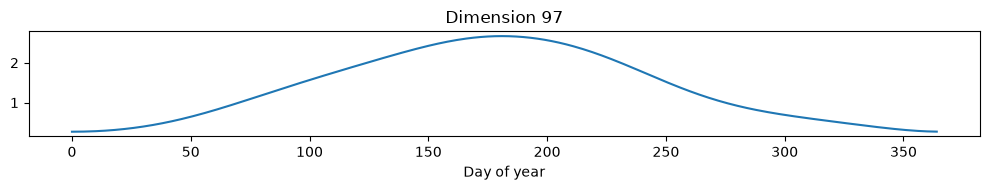

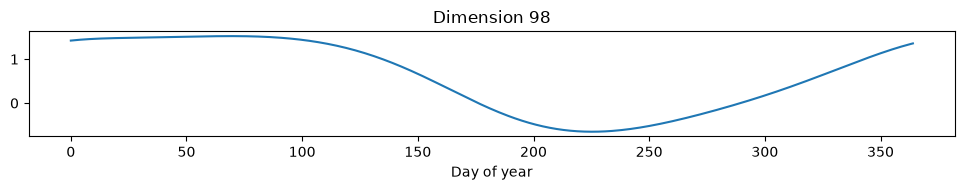

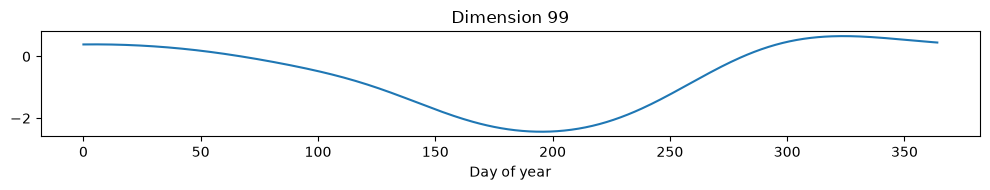

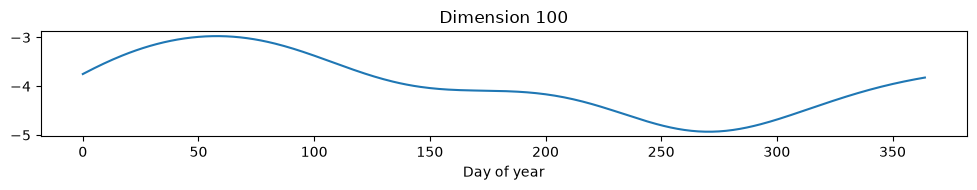

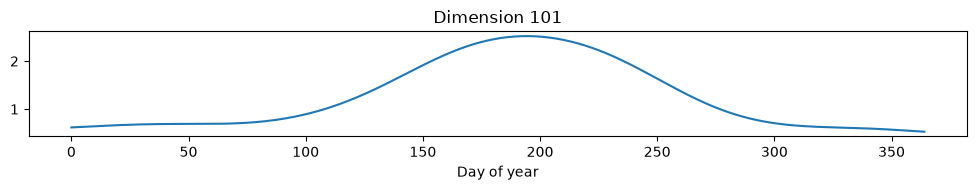

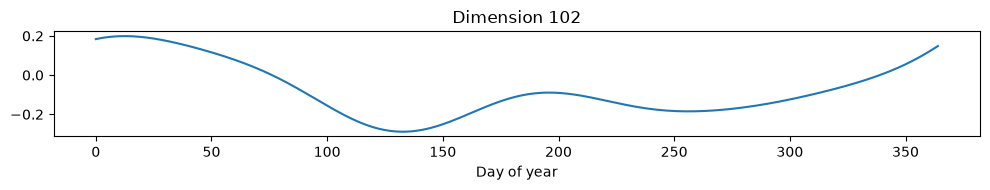

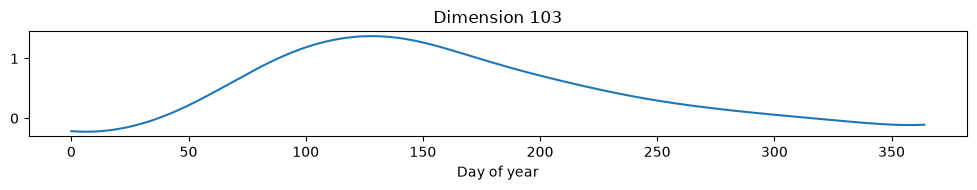

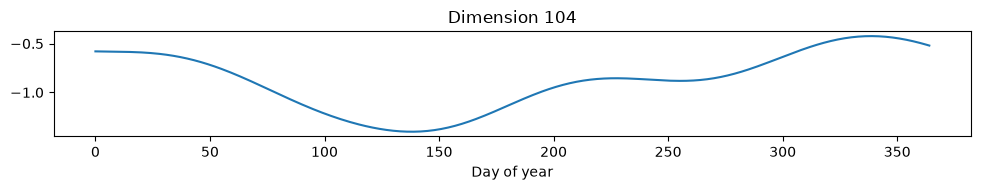

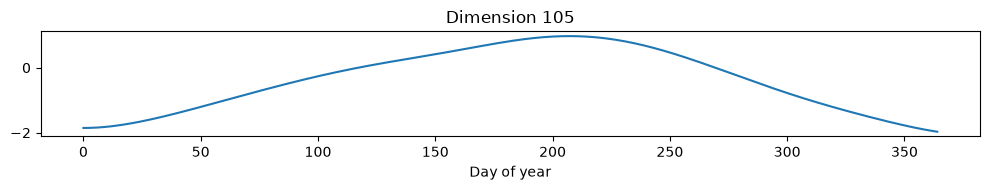

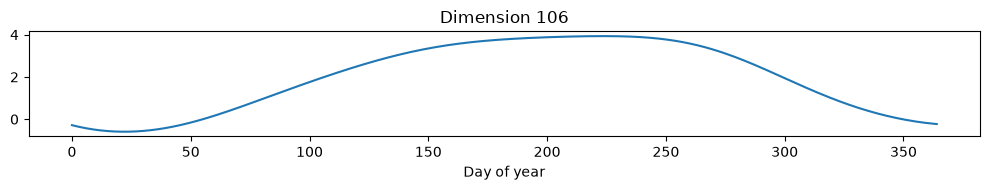

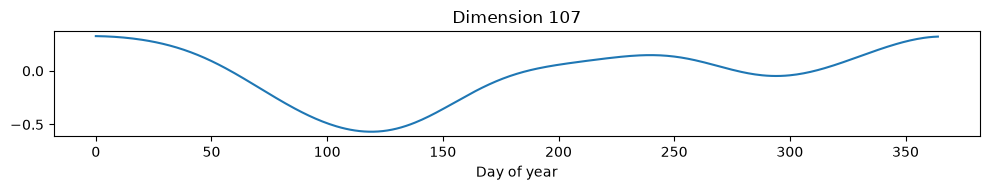

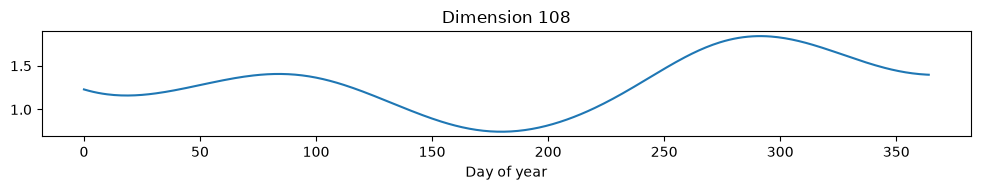

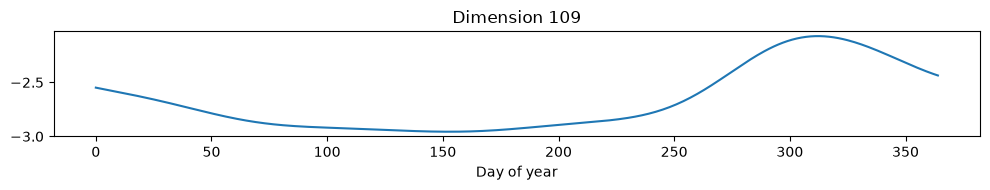

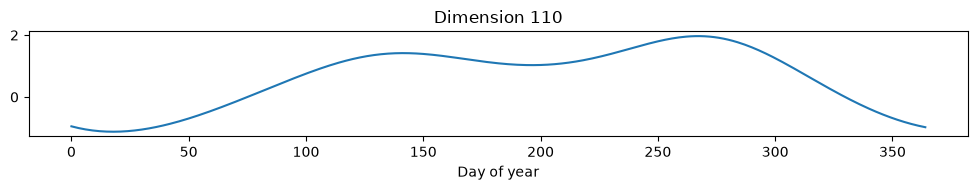

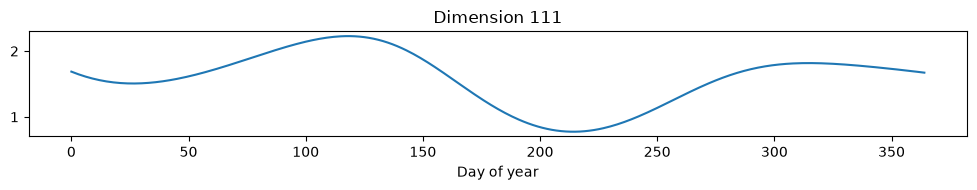

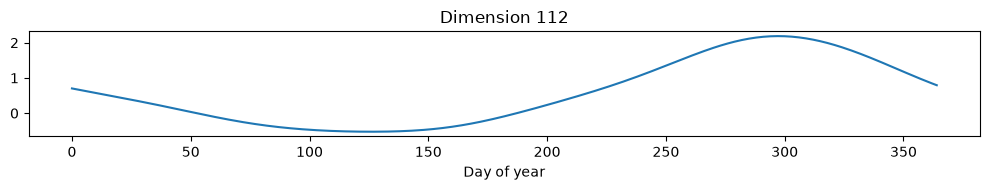

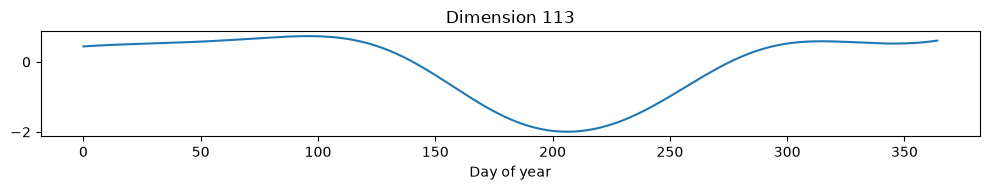

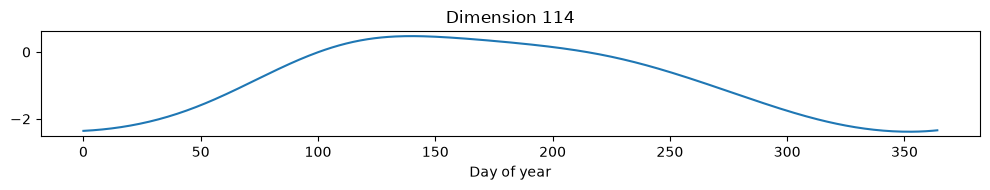

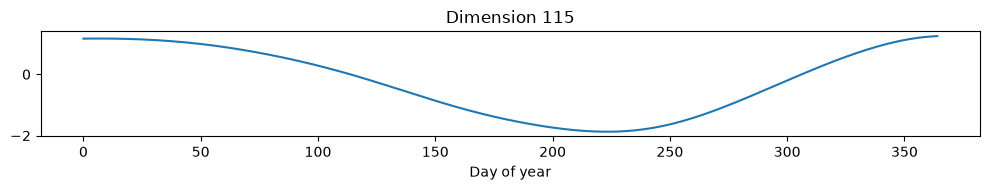

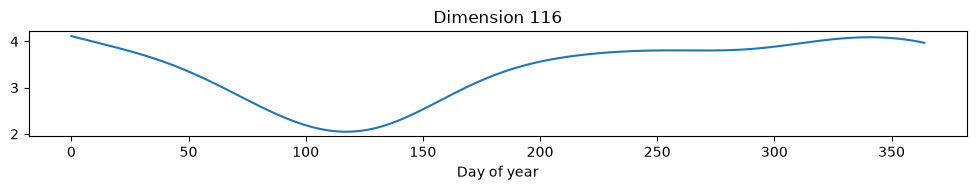

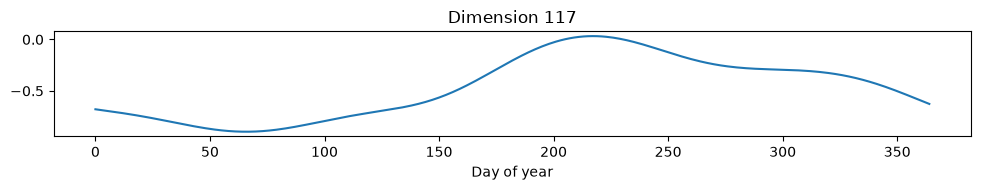

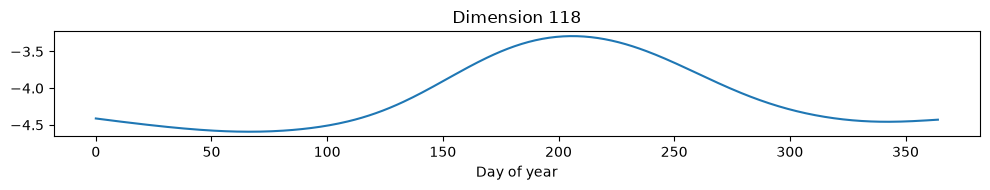

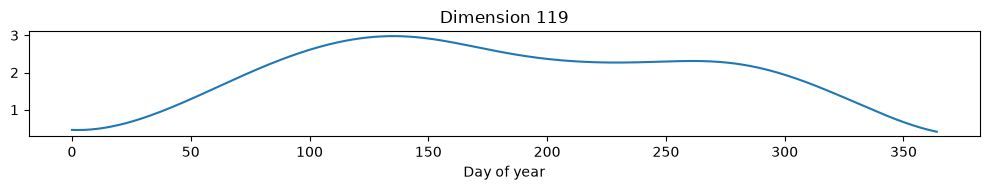

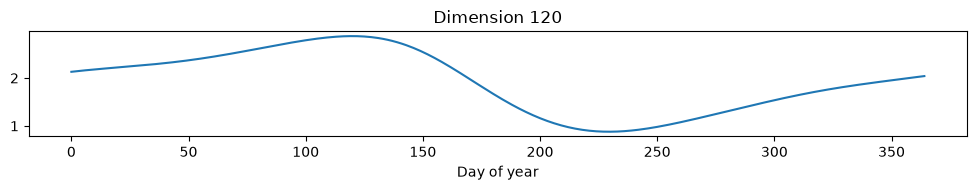

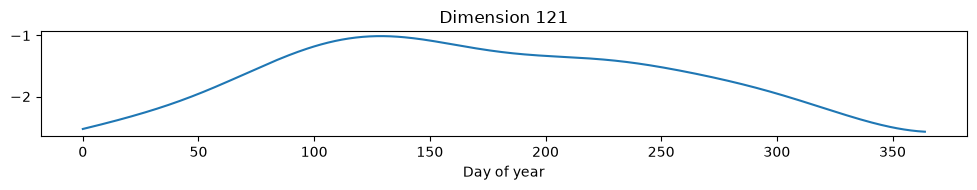

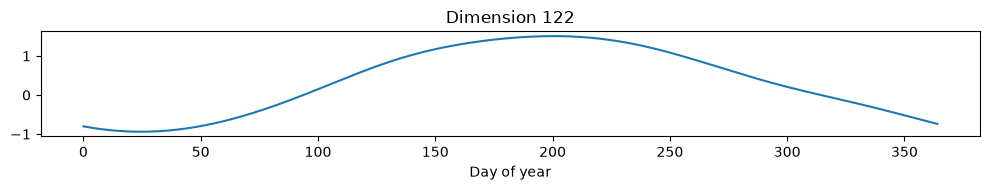

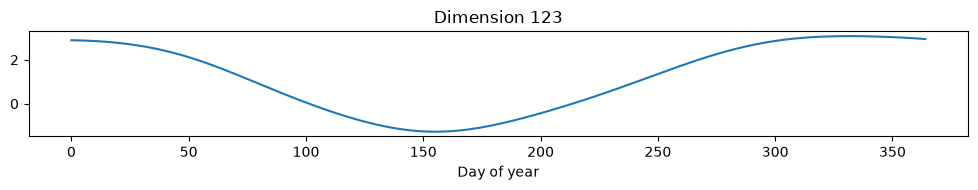

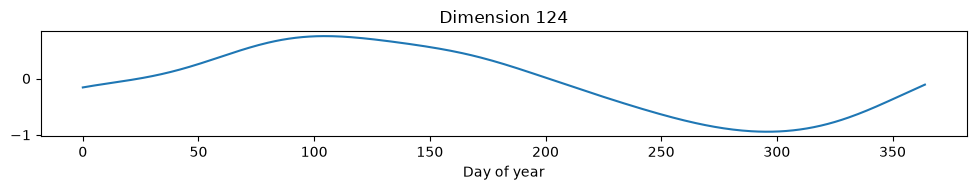

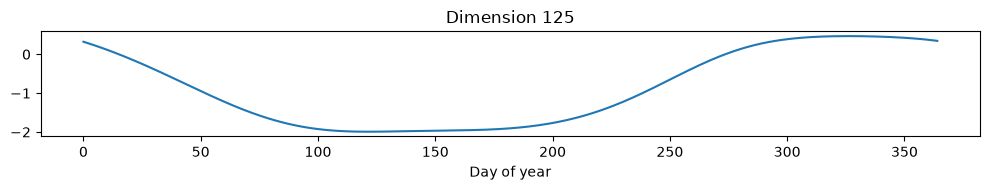

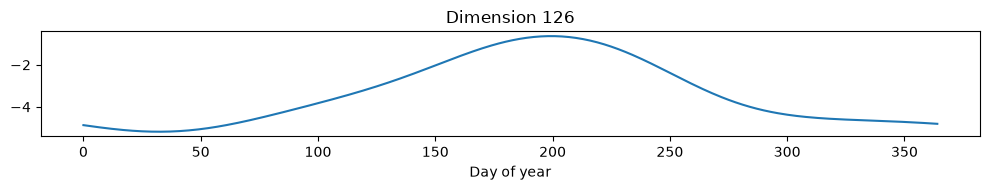

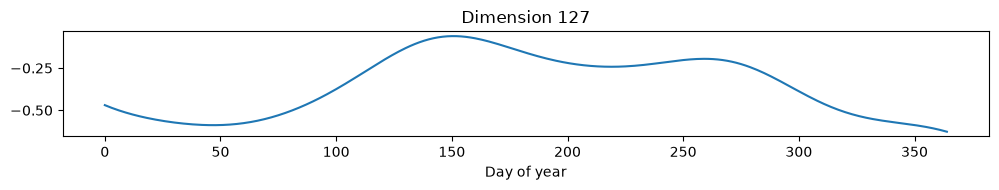

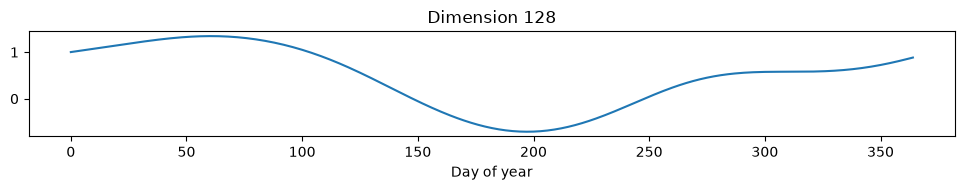

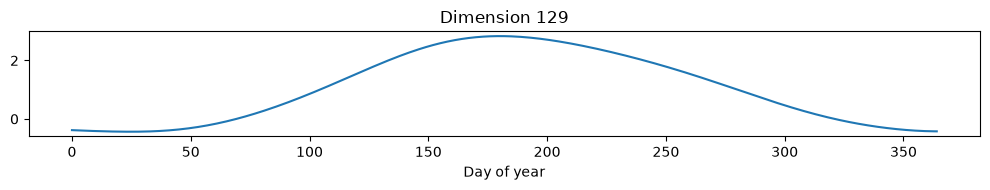

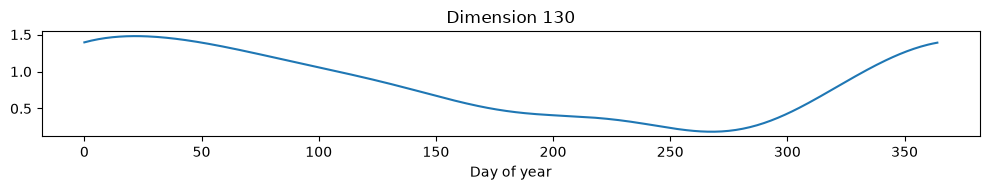

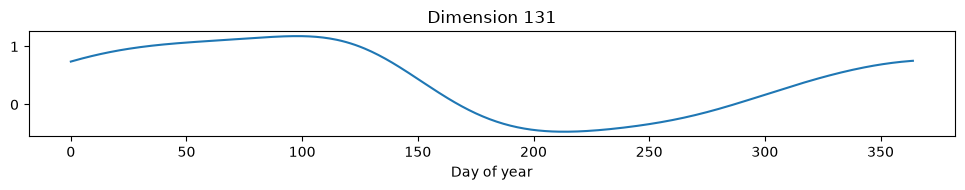

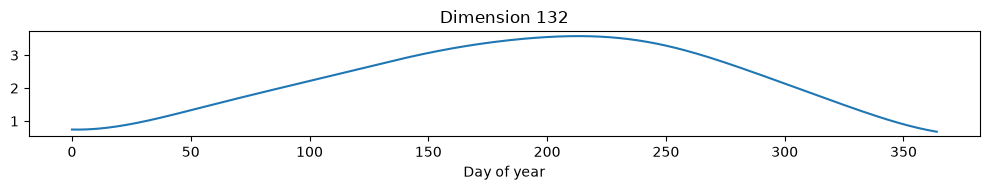

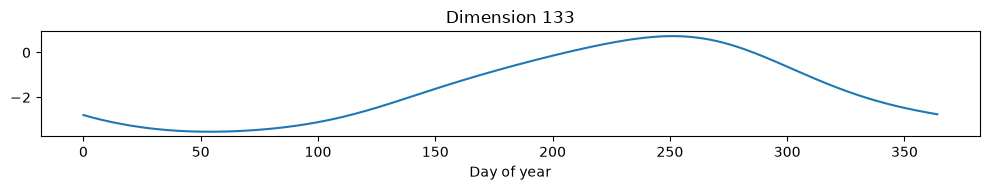

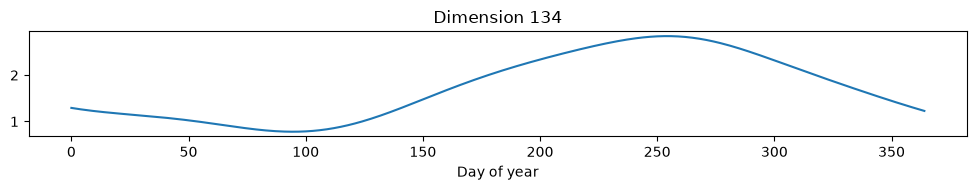

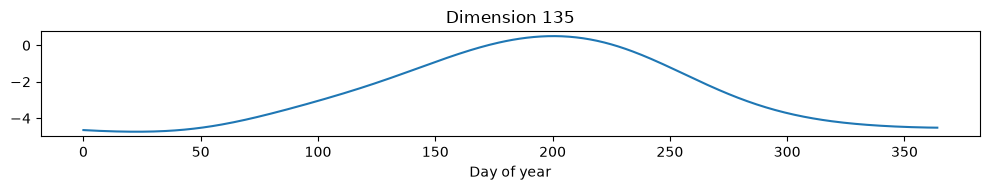

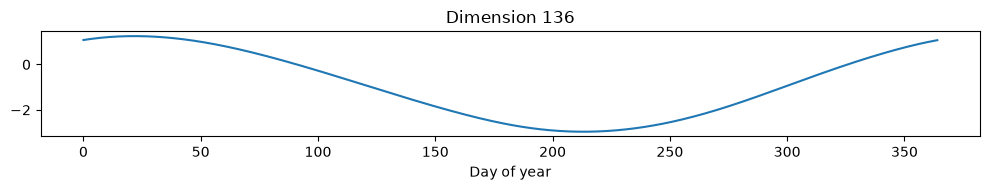

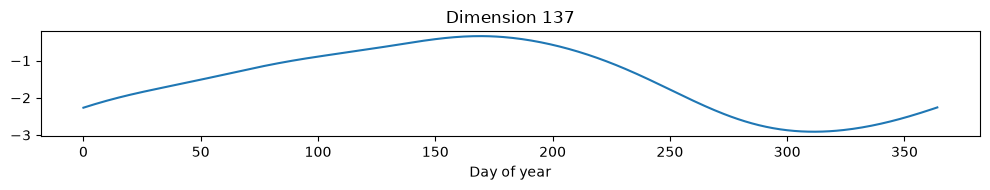

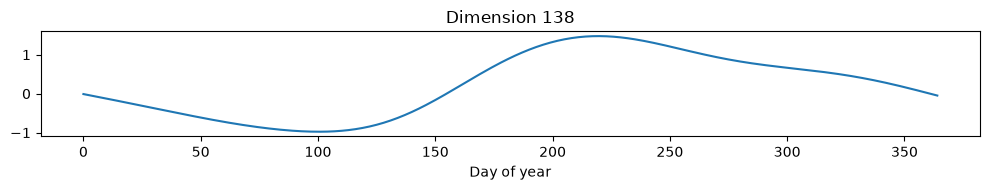

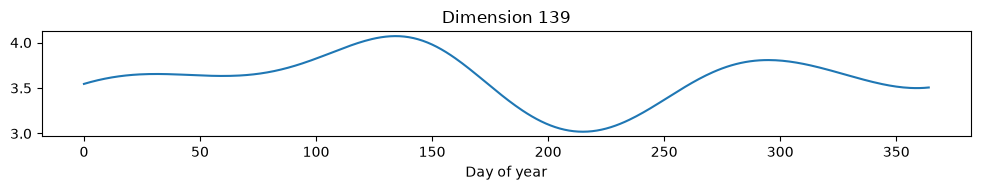

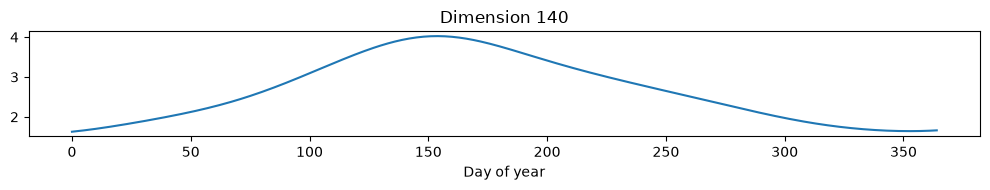

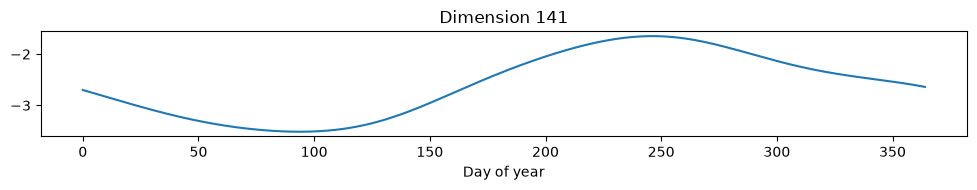

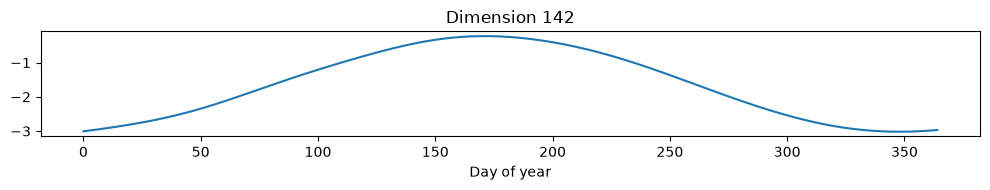

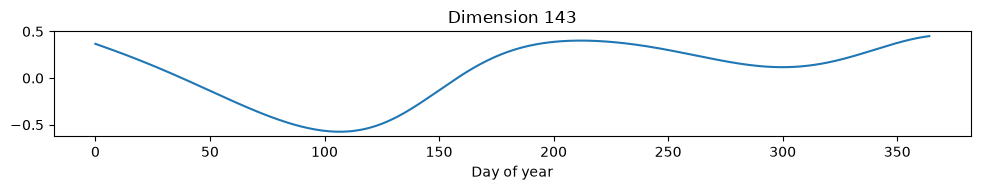

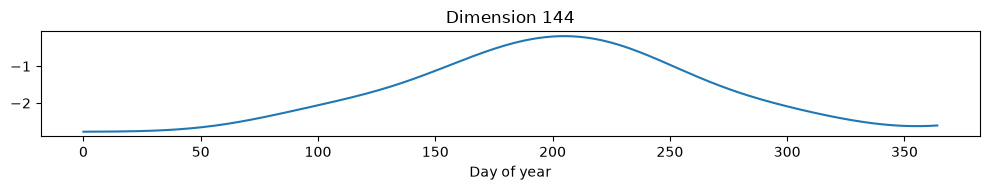

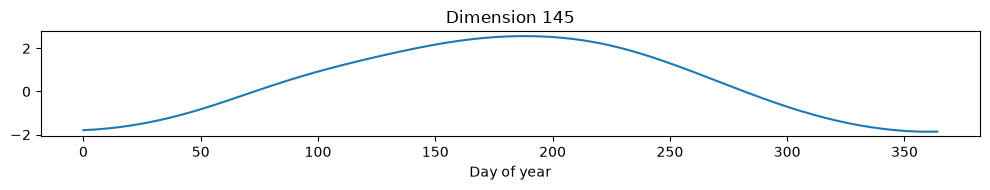

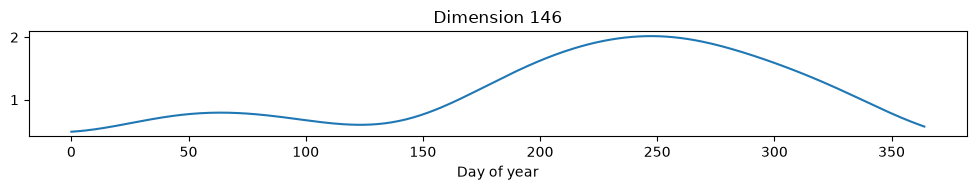

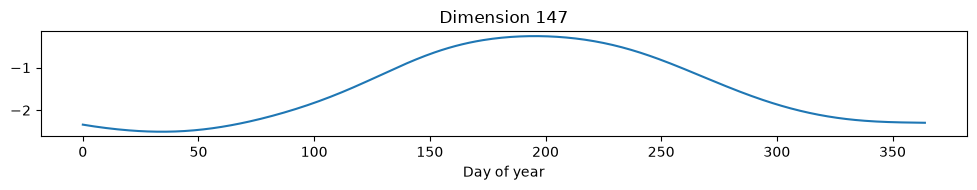

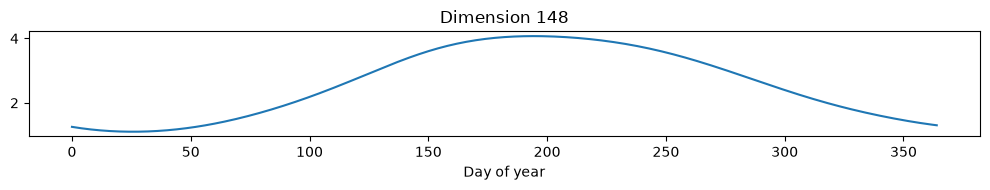

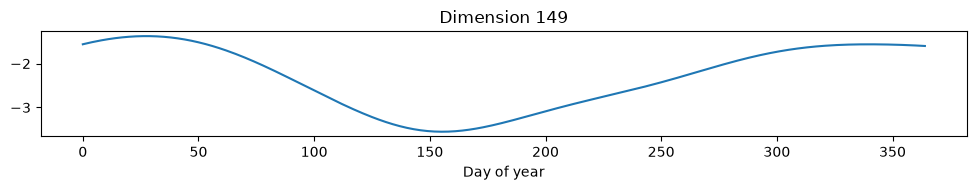

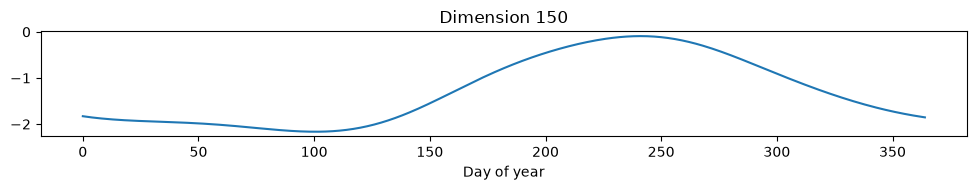

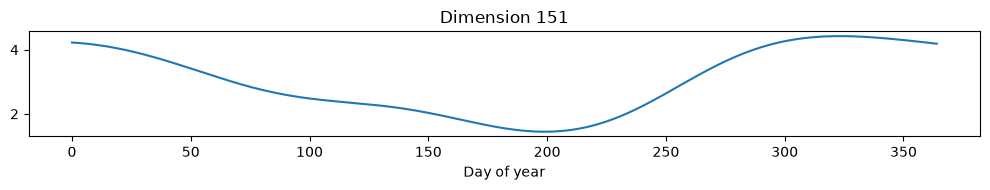

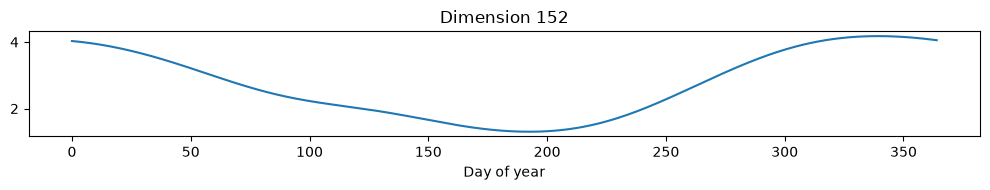

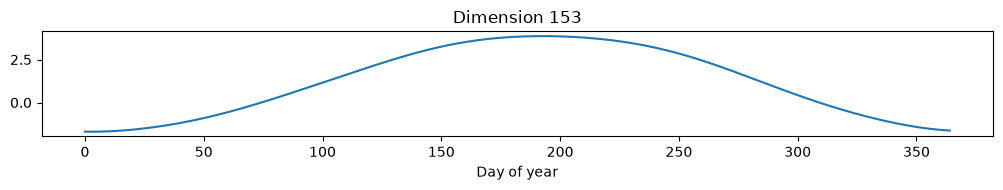

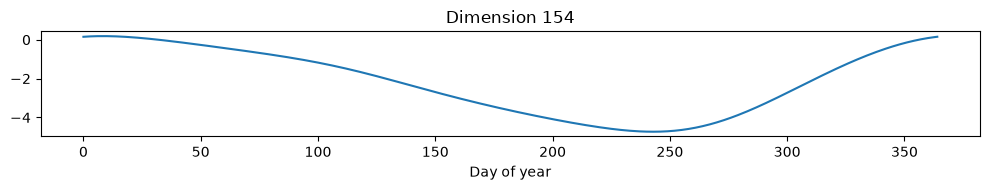

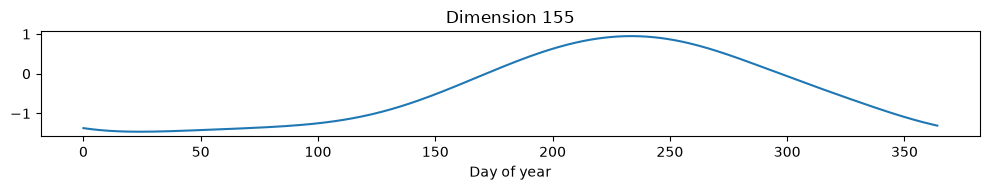

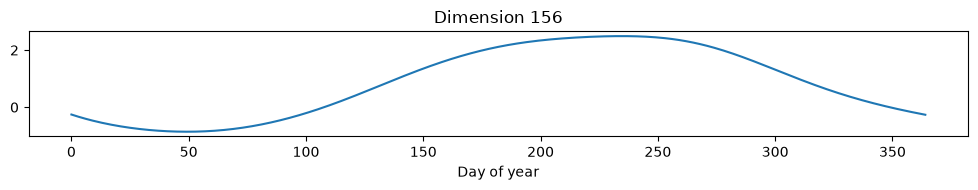

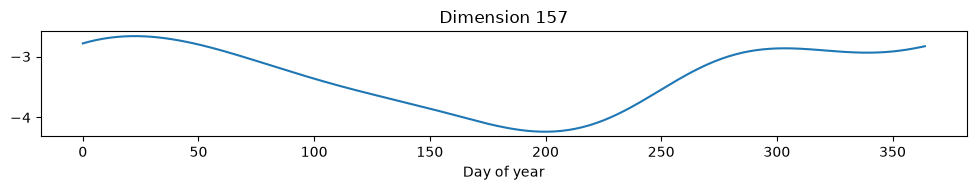

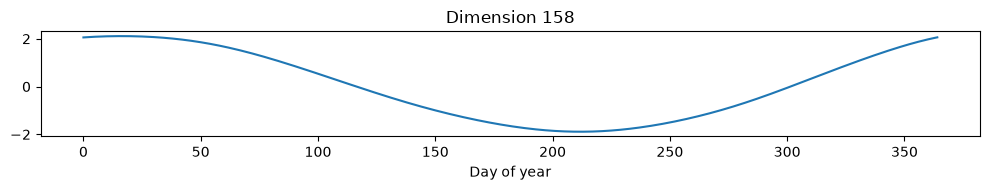

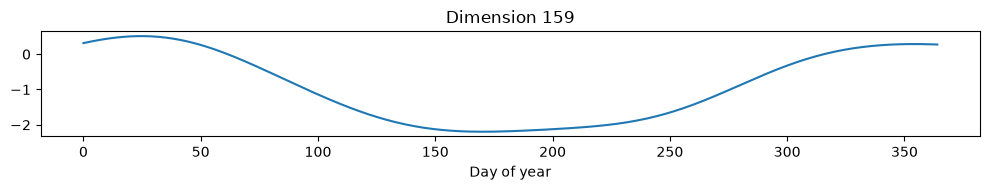

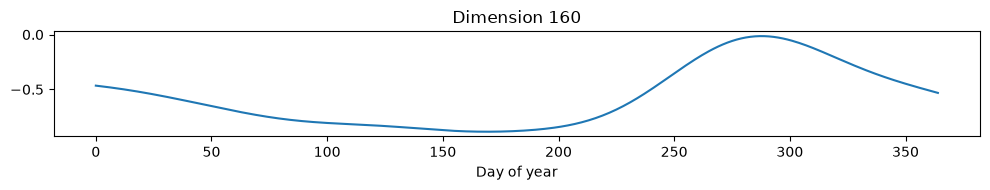

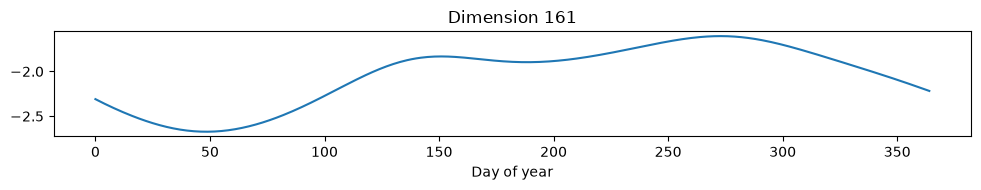

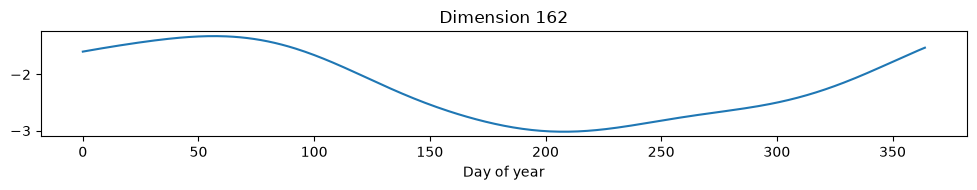

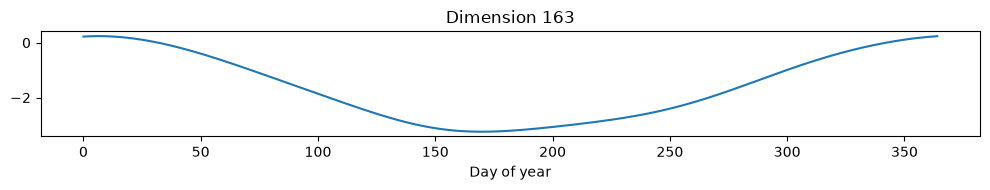

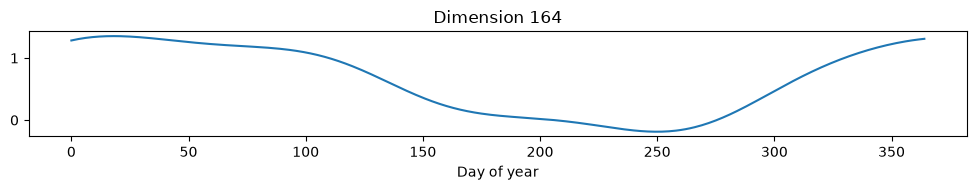

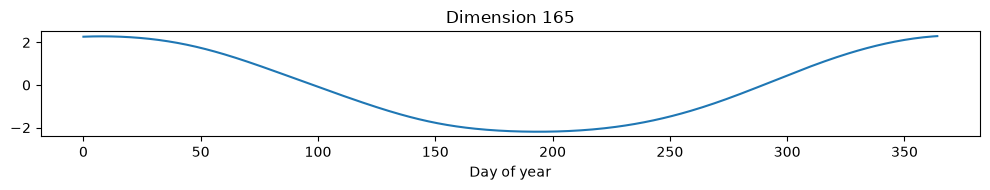

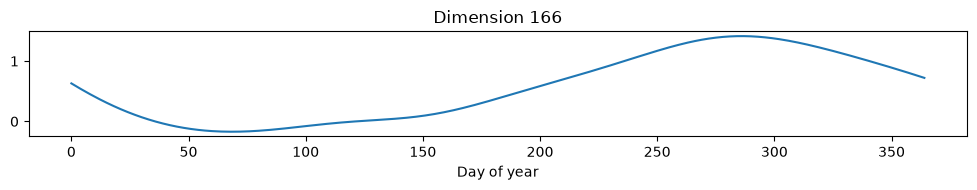

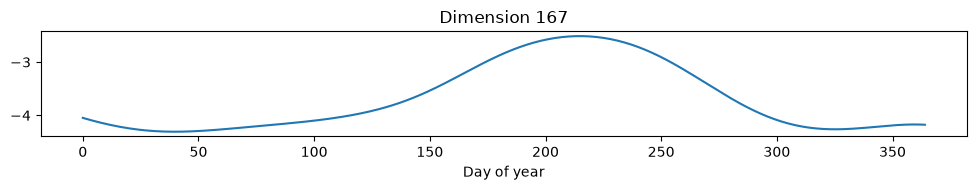

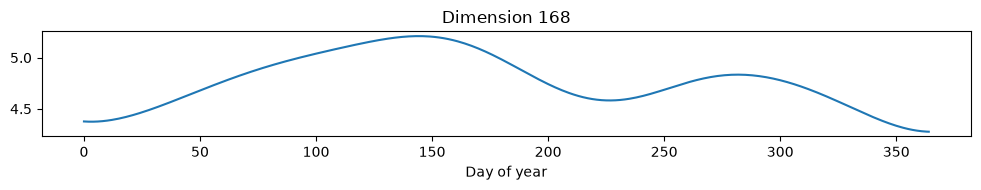

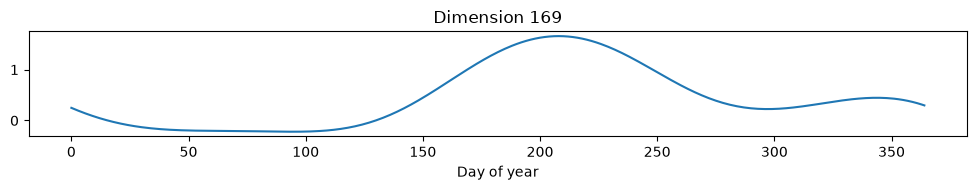

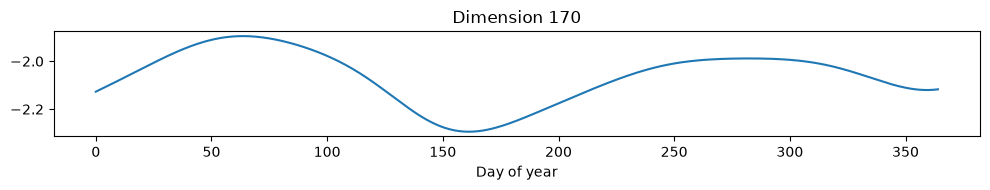

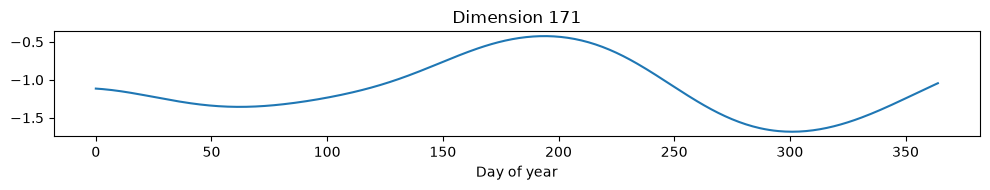

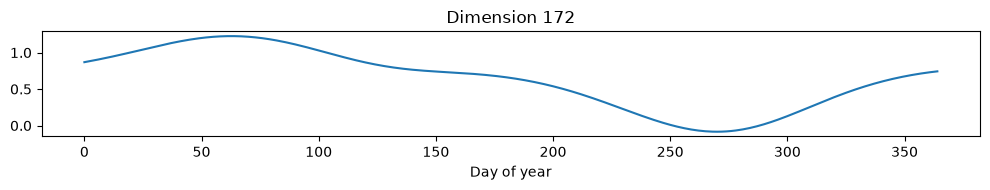

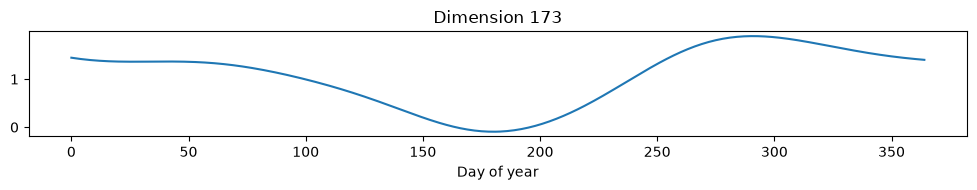

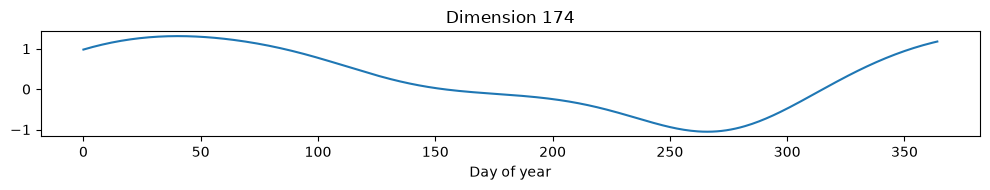

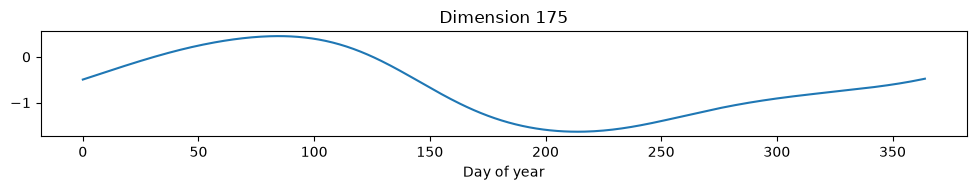

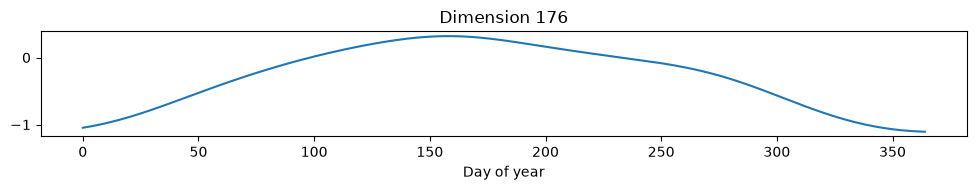

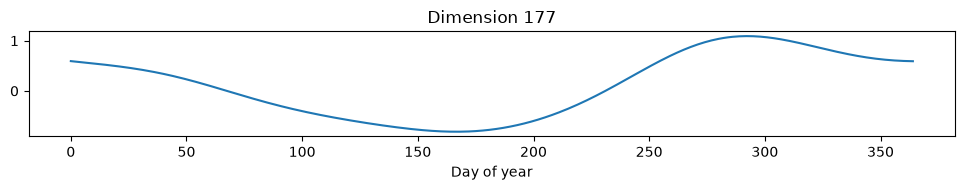

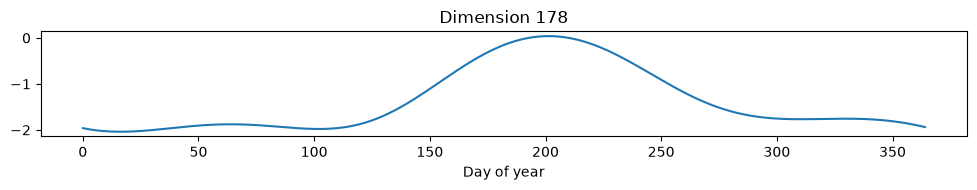

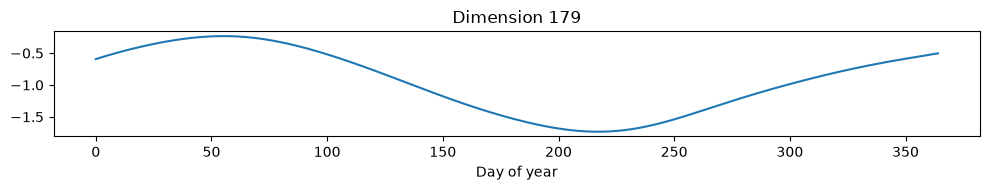

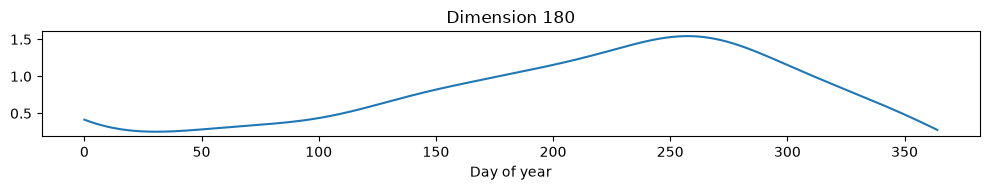

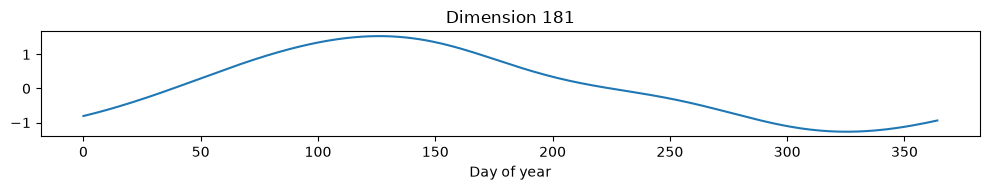

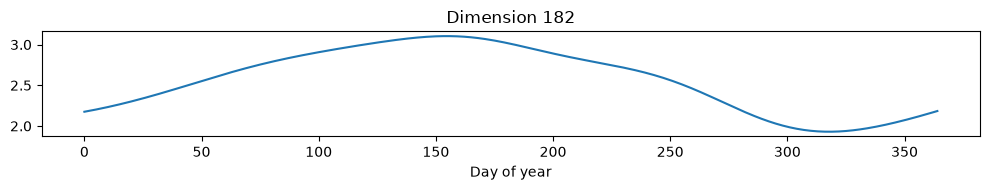

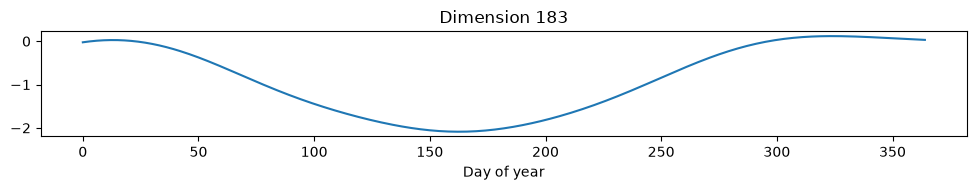

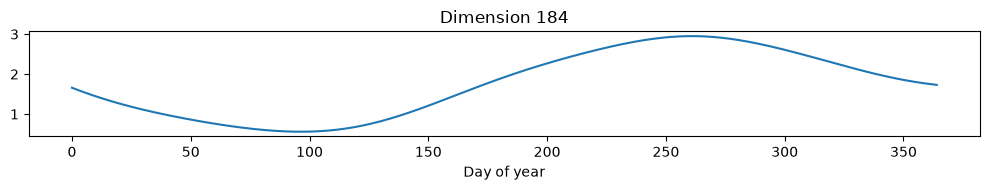

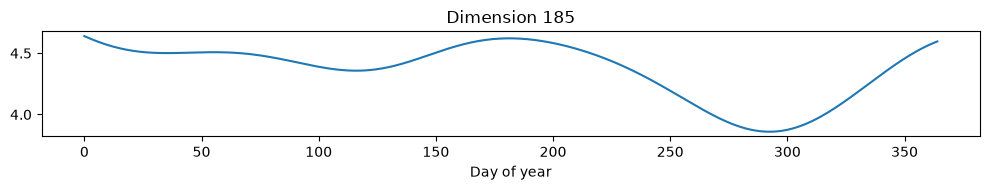

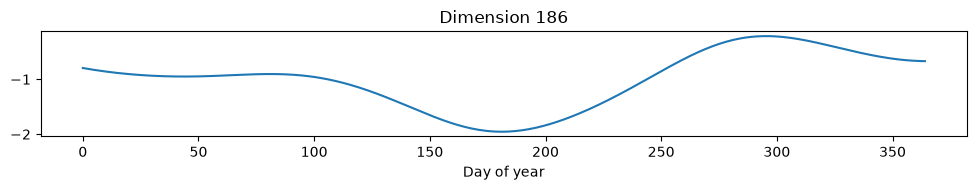

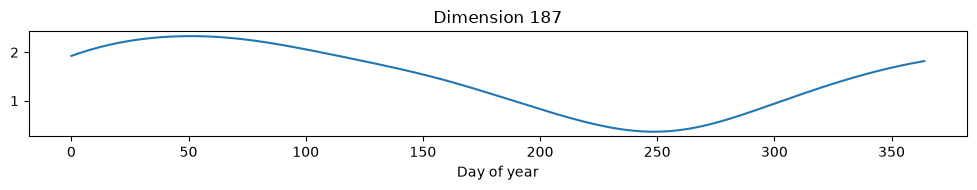

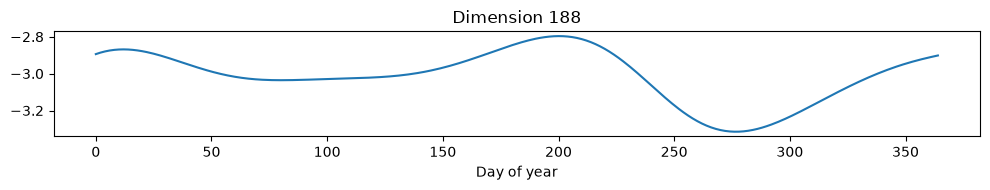

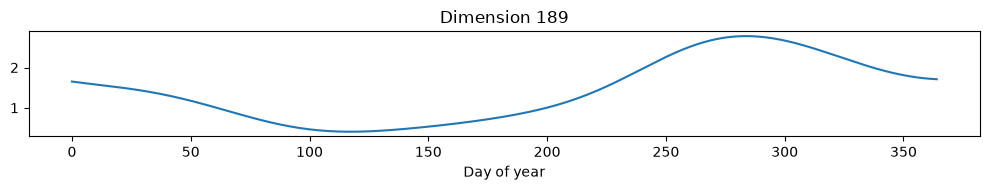

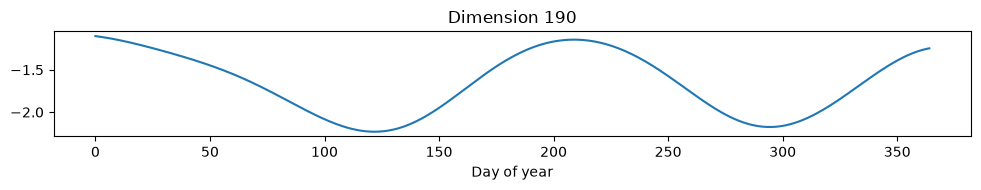

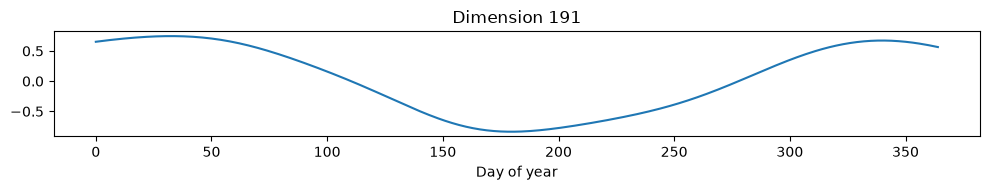

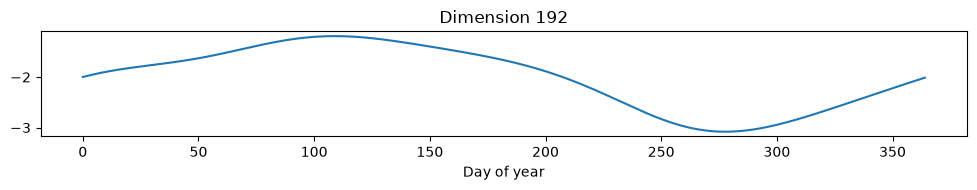

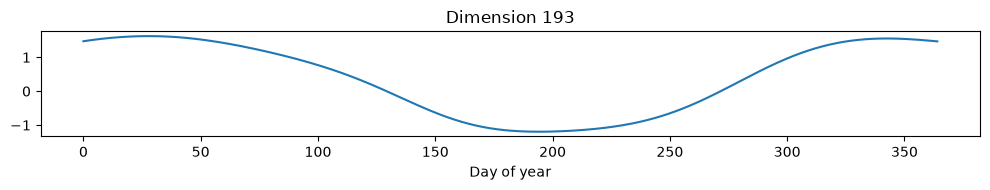

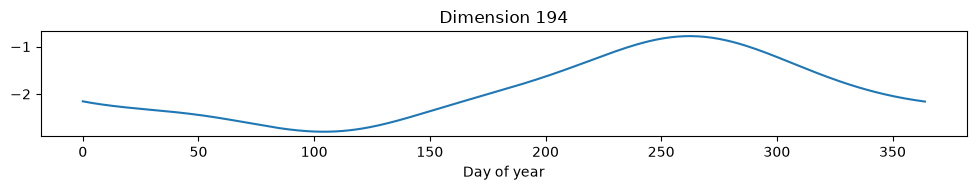

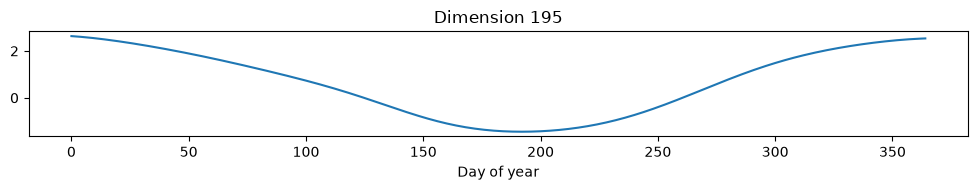

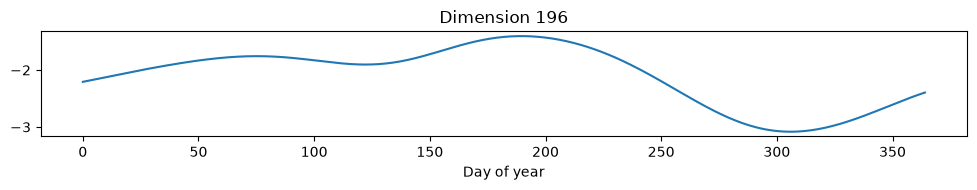

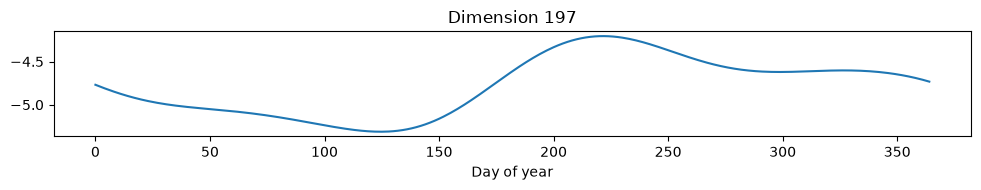

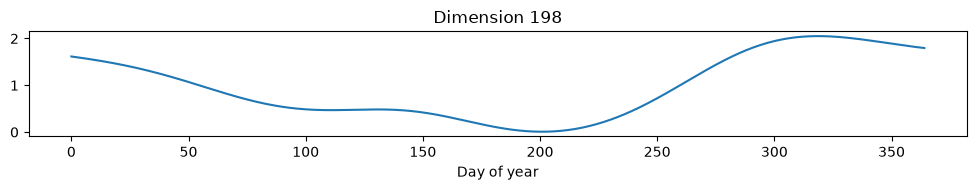

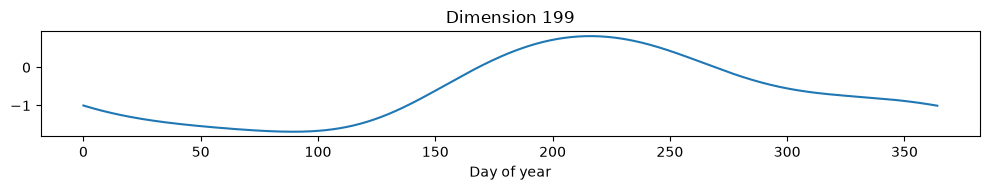

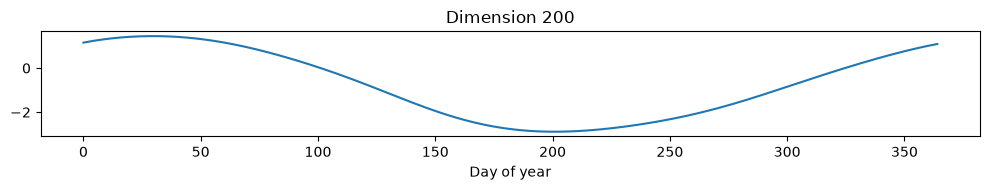

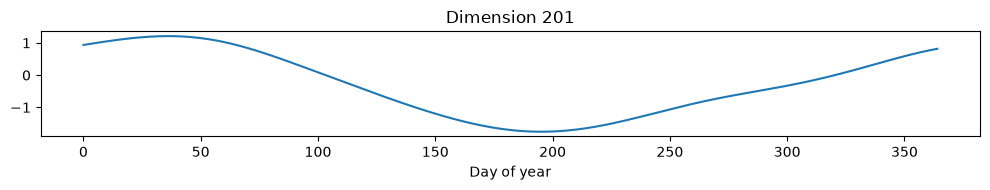

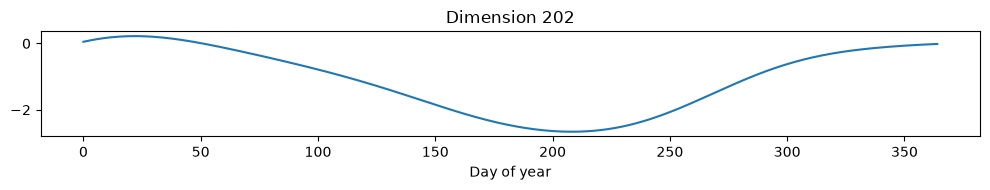

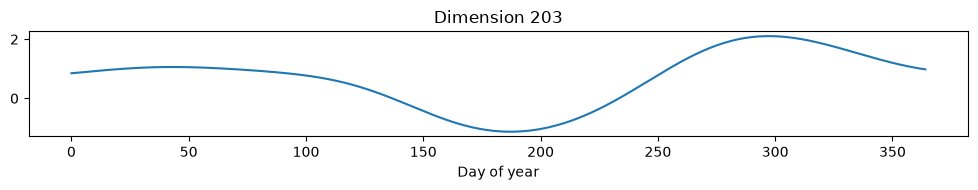

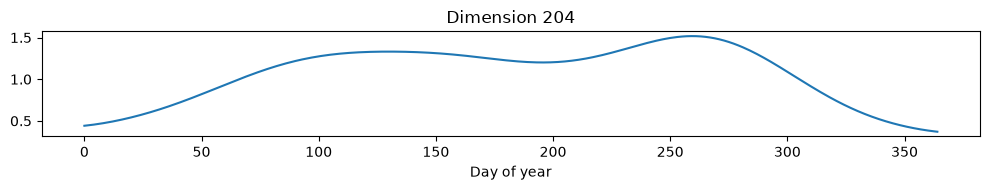

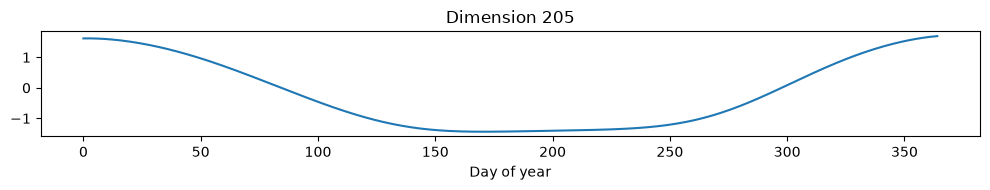

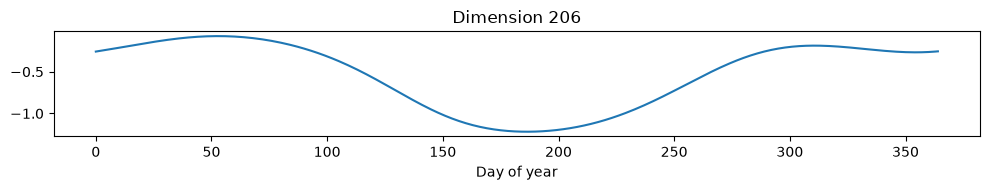

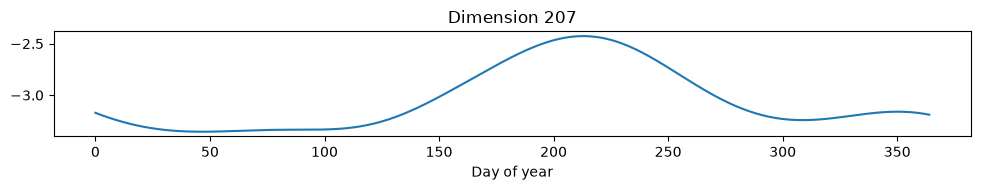

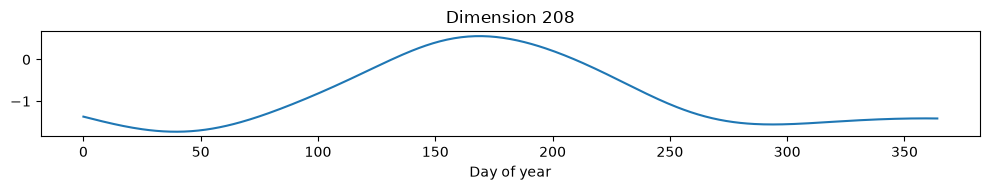

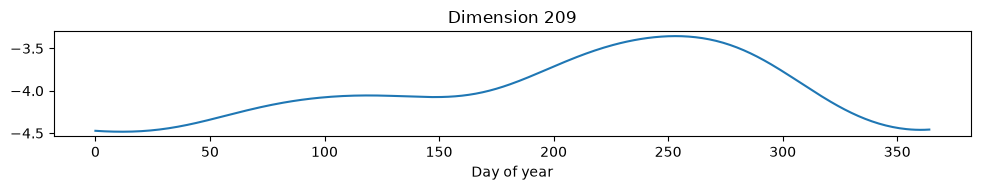

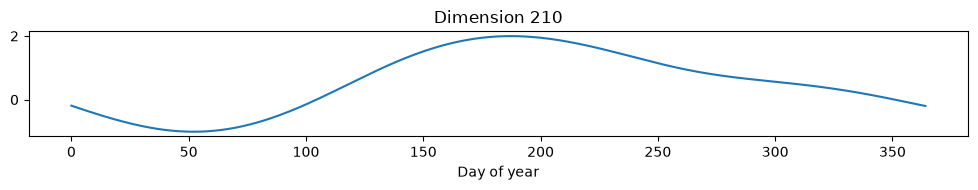

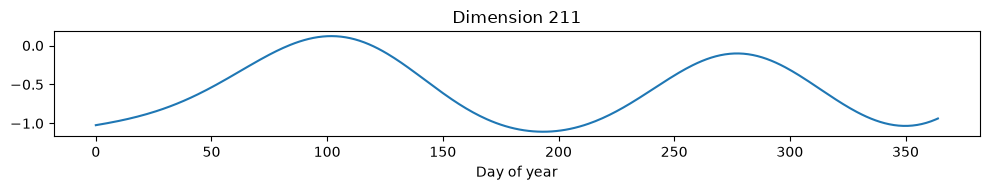

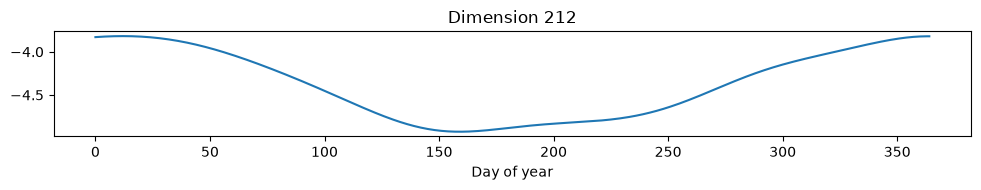

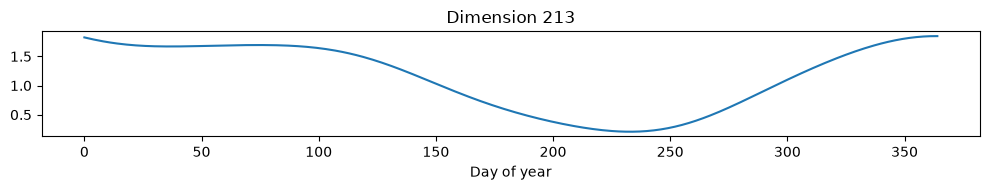

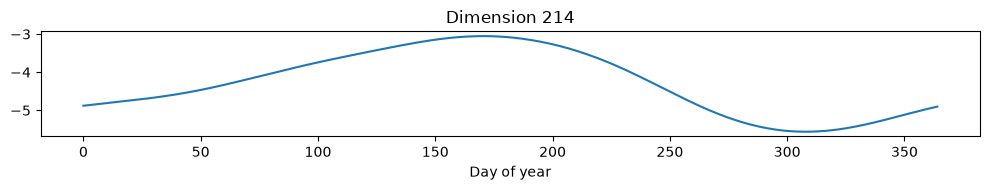

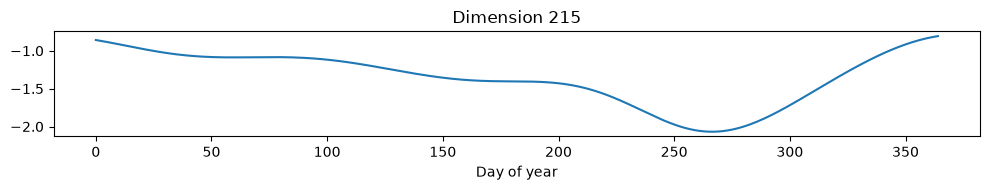

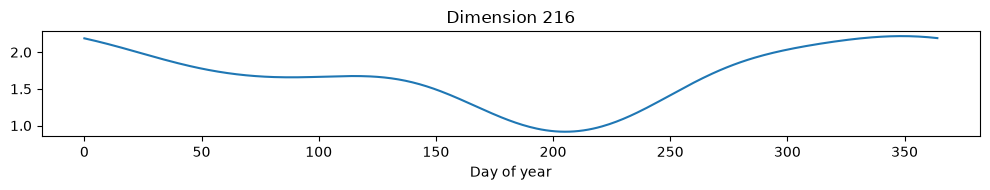

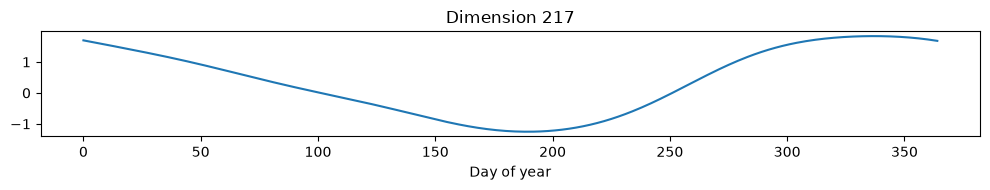

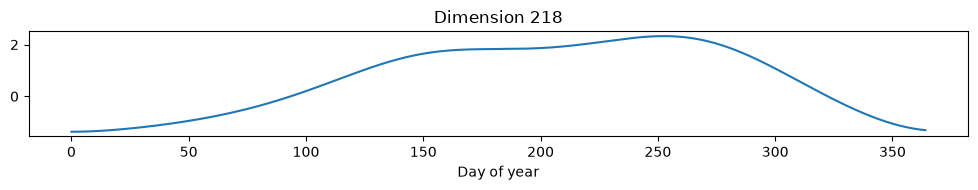

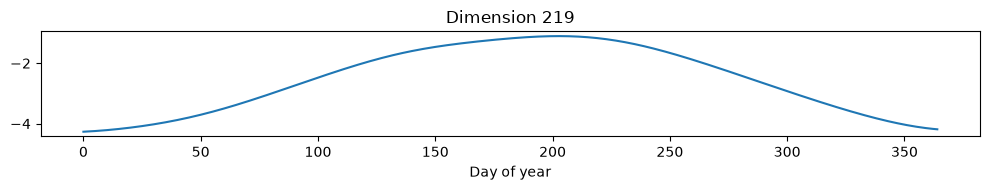

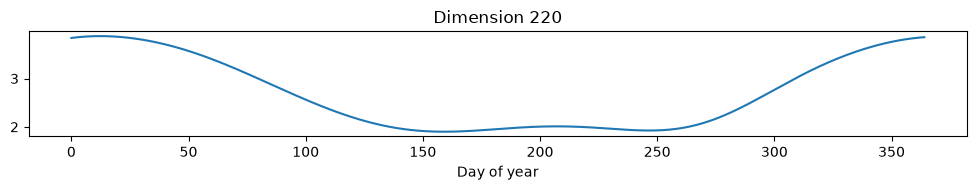

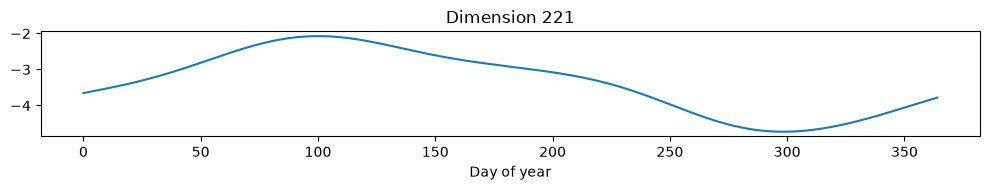

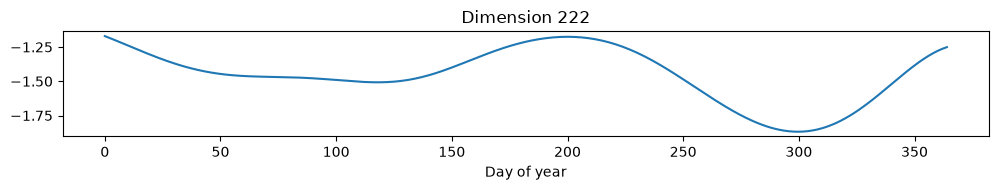

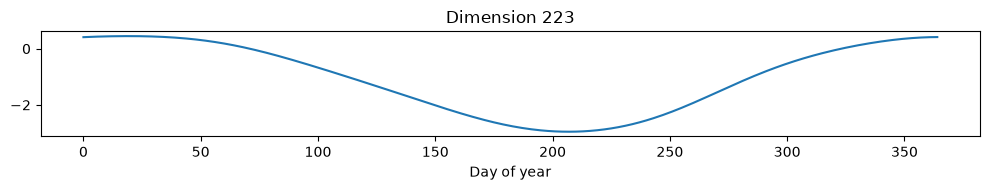

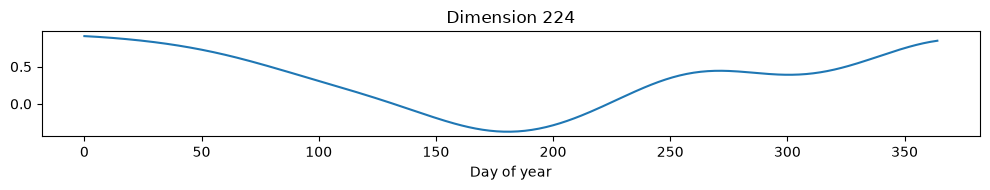

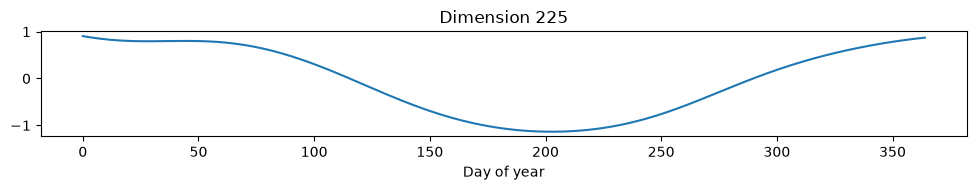

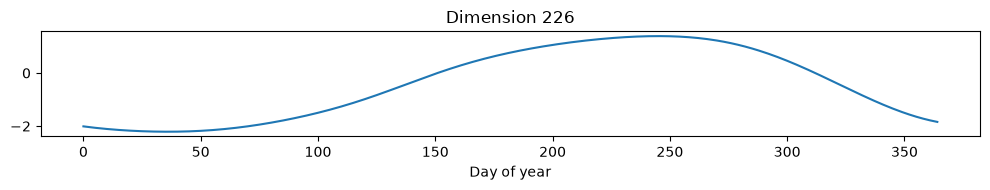

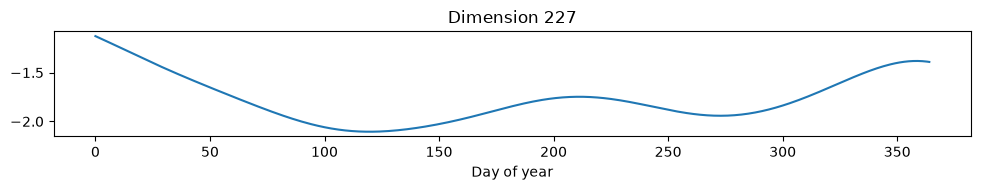

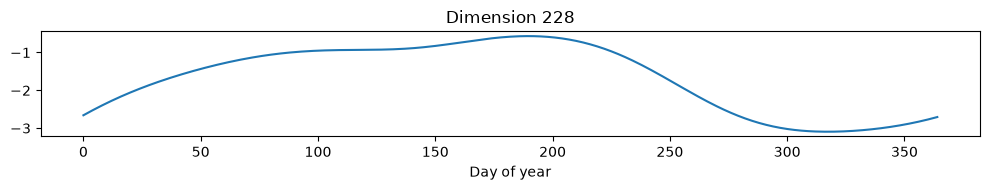

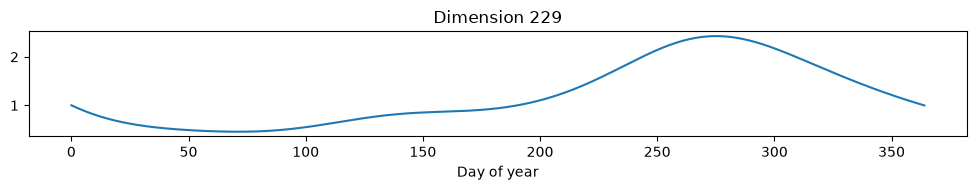

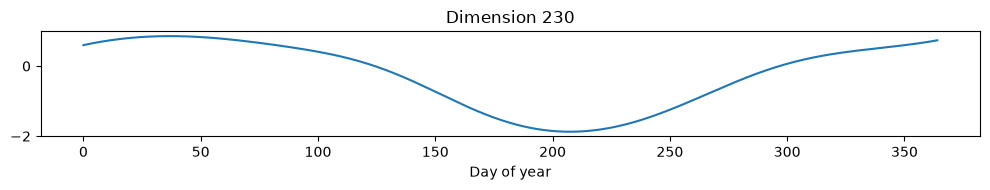

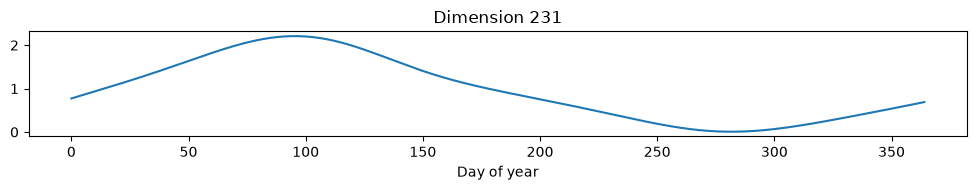

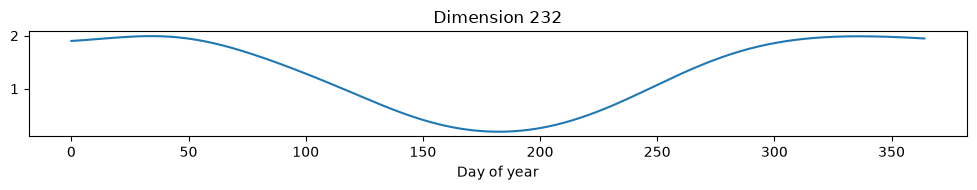

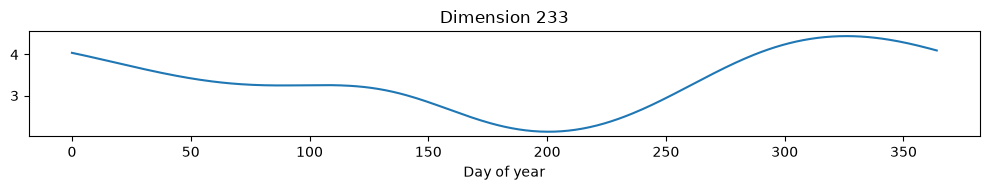

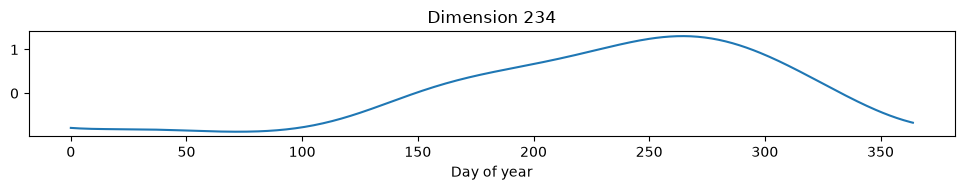

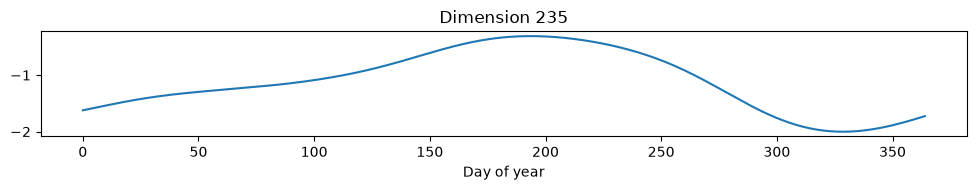

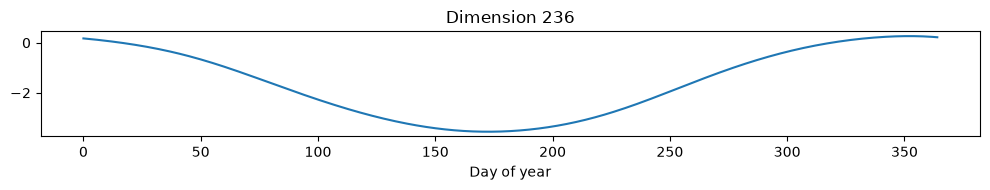

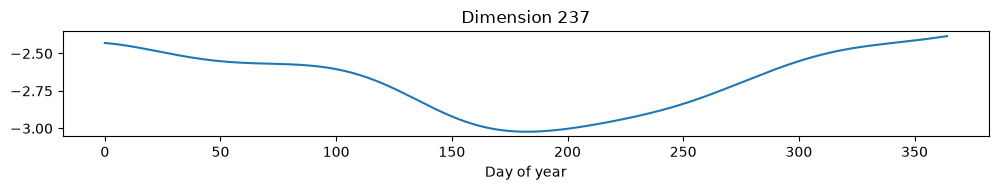

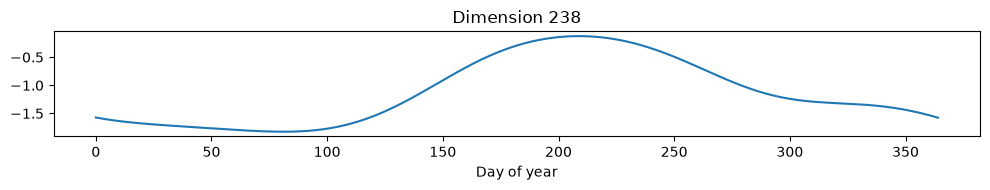

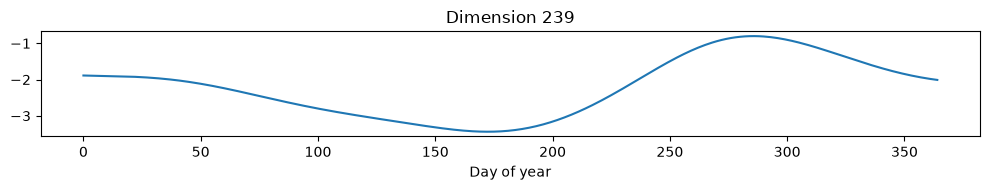

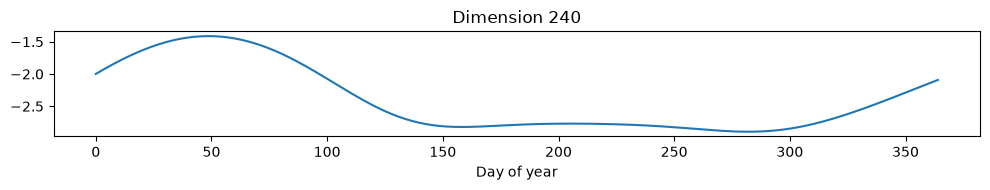

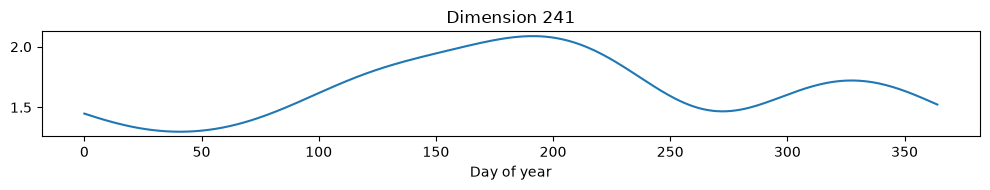

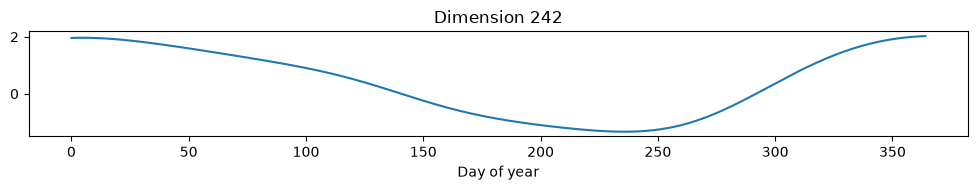

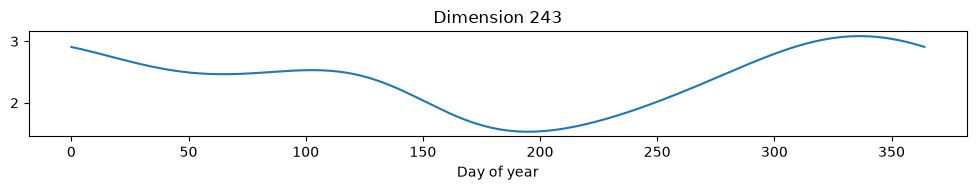

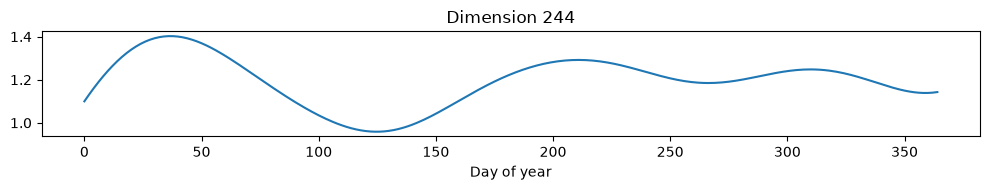

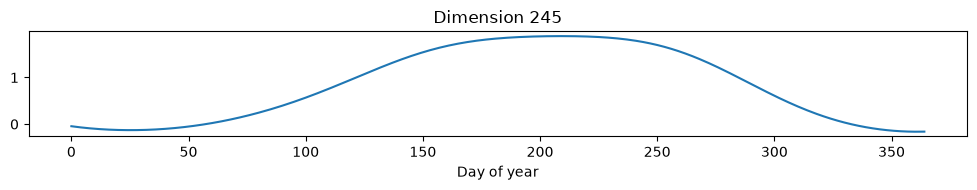

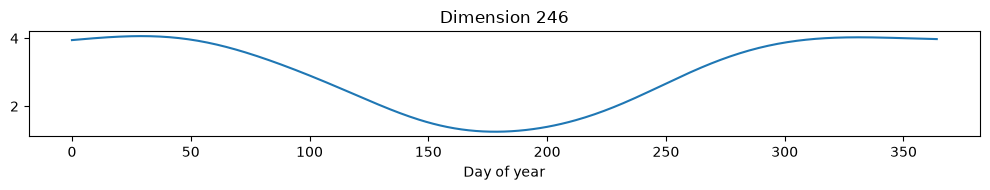

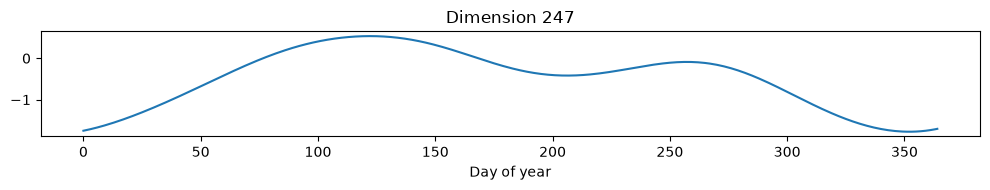

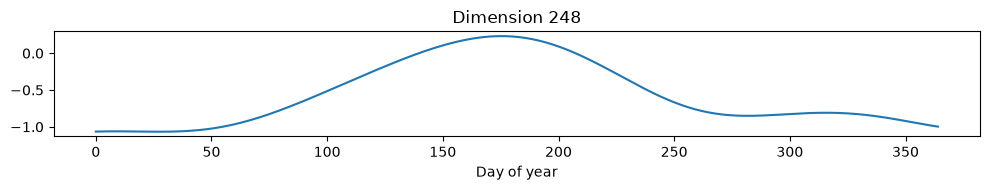

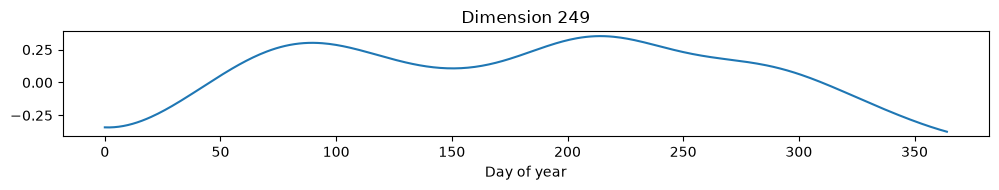

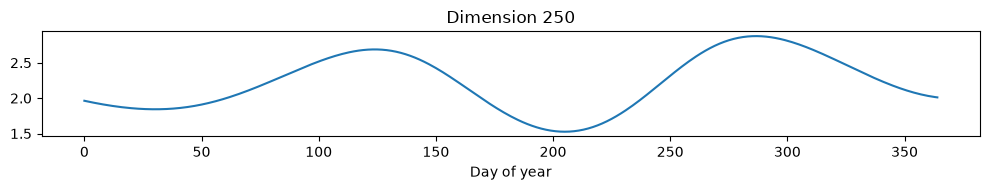

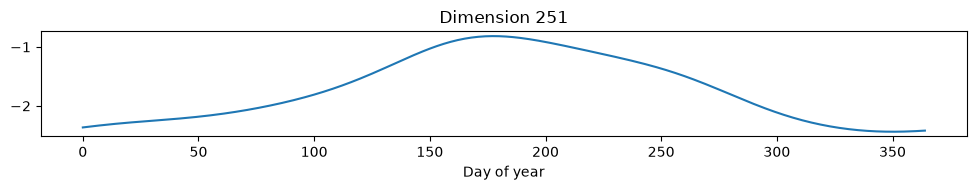

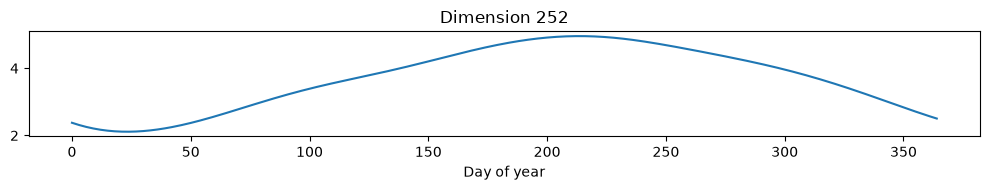

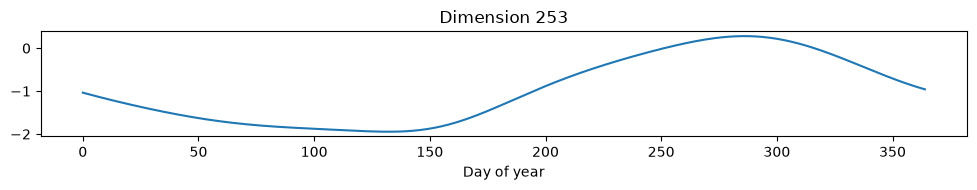

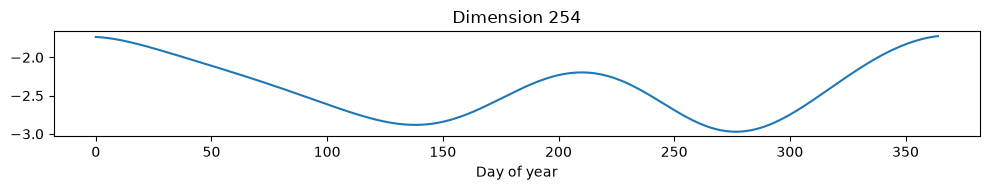

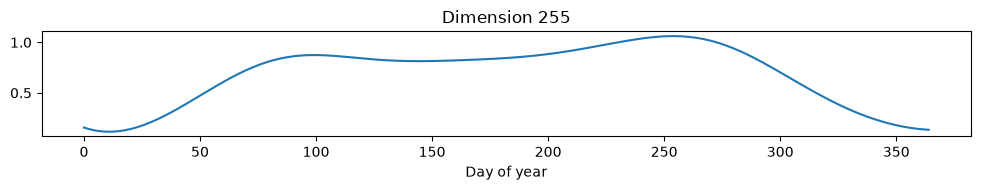

In [11]:
for d in range(embeddings.shape[1]):
    plt.figure(figsize=(10, 2))
    plt.plot(embeddings[:, d])
    plt.title(f"Dimension {d}")
    plt.xlabel("Day of year")
    plt.tight_layout()
    plt.show()

## Sample 30K UAR locations

In [12]:
import geopandas as gpd
from shapely.geometry import Point

world = gpd.read_file("shapefiles/ne_110m_admin_0_countries.shp").union_all()

rng = np.random.default_rng(42)
lons, lats = [], []
while len(lons) < 30_000:
    lon = rng.uniform(-180, 180, 50_000)
    lat = rng.uniform(-90, 90, 50_000)
    mask = [world.contains(Point(x, y)) for x, y in zip(lon, lat)]
    lons.extend(lon[mask])
    lats.extend(lat[mask])

lons = np.array(lons[:30_000])
lats = np.array(lats[:30_000])

In [13]:
dates = pd.date_range("2017-01-01", "2017-12-31", freq="D")
timestamps = dates.astype("datetime64[s]").astype(np.int64)  # (365,)
N_days = len(timestamps)
N_locs = len(lons)

In [14]:
lons_rep = np.repeat(lons, N_days)       # (30000*365,)
lats_rep = np.repeat(lats, N_days)
ts_rep   = np.tile(timestamps, N_locs)   # (30000*365,)


: 

In [ ]:
all_embs = encoder.encode(lons_rep, lats_rep, posix_timestamp=ts_rep)
all_embs = all_embs.reshape(N_locs, N_days, -1)  # (30000, 365, D)


### Visualize

In [ ]:
D = all_embs.shape[2]

for d in range(D):
    plt.figure(figsize=(10, 3))
    plt.plot(all_embs[:, :, d].T, color="steelblue", alpha=0.01, linewidth=0.5)
    plt.title(f"Dimension {d}")
    plt.xlabel("Day of year")
    plt.tight_layout()
    plt.show()

### See if one channel (pick randomly) varies over 1 week, 1 month,...

In [ ]:
d=1

In [ ]:
plt.figure(figsize=(10, 3))
plt.plot(all_embs[:, 1:7, d].T, color="steelblue", alpha=0.01, linewidth=0.5)
plt.title(f"Dimension {d}")
plt.xlabel("Day of year")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 3))
plt.plot(all_embs[:, 1:31, d].T, color="steelblue", alpha=0.01, linewidth=0.5)
plt.title(f"Dimension {d}")
plt.xlabel("Day of year")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 3))
plt.plot(all_embs[:, 1:91, d].T, color="steelblue", alpha=0.01, linewidth=0.5)
plt.title(f"Dimension {d}")
plt.xlabel("Day of year")
plt.tight_layout()
plt.show()